# M08 · Tests statistiques — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/m08_tests/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | M08.1 à M08.9, M08.13 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | M08.16 | Le test binomial exact · `binomial_test` | 🔨 | ★ | 15 |
|  | M08.17 | Le test par permutation à deux échantillons · `permutation_test` | 🔨 | ★★ | 25 |
|  | M08.18 | Les intervalles de Wilson et de Student · `proportion_ci, paired_difference_ci` | 🔨 | ★ | 20 |
|  | M08.19 | Bonferroni, l'AIC et le BIC · `bonferroni, aic_bic` | 🔨 | ★ | 10 |
|  | M08.20 | `scipy.stats.binomtest`, `permutation_test` et `ttest_rel` contre tes fonctions | 📦 | ★ | 15 |
| B | M08.21 | Prédire : sous H0, quelle part de 1 000 p-valeurs tombe sous 0,05 ? | 🔮 | ★ | 10 |
|  | M08.22 | La puissance d'un test par permutation, selon l'effet et la taille des groupes | 🔬 | ★★ | 25 |
|  | M08.23 | La loi de la statistique sous H0, et la p-valeur comme une aire | 🎨 | ★ | 15 |
| C | M08.24 | Chasse à l'erreur : une p-valeur nulle, un test unilatéral choisi après coup, Bonferroni à l'envers | 🐛 | ★ | 15 |
|  | M08.25 | Tester un test : un pytest qui vérifie l'uniformité des p-valeurs sous H0 | 🛠️ | ★ | 15 |
|  | M08.26 | Défi : retrouver les trois vraies features parmi cinquante, avec au plus un faux positif | 🏆 | ★★★ | 25 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : test binomial exact, test par permutation exhaustif, risques et puissance, taille d'échantillon, intervalles de Wald, de Wilson et de Student, comparaisons multiples, AIC et BIC, facteur de Bayes, importance par permutation.
- Écrire les six fonctions de `mymath/testing.py` et les tester, puis comparer avec `scipy.stats`.
- Prédire la loi des p-valeurs, mesurer une puissance, tracer une loi nulle exacte, chasser des erreurs, tester un test, choisir des features parmi cinquante.

**Rappel express.** p-valeur = $P_{H_0}(\text{statistique au moins aussi extrême que l'observation})$ ; risque de type I $\alpha$ = $P_{H_0}(\text{rejeter})$, puissance $1 - \beta$ = $P_{H_1}(\text{rejeter})$ ; $n = \Big(\frac{(z_{1-\alpha} + z_{1-\beta})\,\sigma}{\delta}\Big)^2$ ; permutation : $\frac{C + 1}{B + 1}$ ; Wald $\hat{p} \pm z\sqrt{\hat{p}(1 - \hat{p})/n}$ ; Student apparié $\bar{d} \pm t_{n-1}\,s_d/\sqrt{n}$ ; Bonferroni $\min(1, m\,p_i)$ ; AIC $= 2k - 2\ln L$, BIC $= k\ln n - 2\ln L$ ; $\mathrm{BF}_{12} = \frac{p(\mathcal{D} \mid M_1)}{p(\mathcal{D} \mid M_2)}$.

## Partie 0 · Vérifier tes exercices papier (✏️ M08.1 à M08.9, 🔗 M08.13)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question ;
- une fraction irréductible entre guillemets, `"7/9"` ;
- une liste `[-1.5, 2.5]` (deux bornes, une liste de valeurs), ou `True` / `False`.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed exactly from the statements
import math
from statistics import NormalDist

import numpy as np
from scipy.stats import t as student


def binom_tail(c, n, p):
    """P(K ≥ c) for K of law B(n, p)."""
    return sum(math.comb(n, j) * p ** j * (1 - p) ** (n - j) for j in range(c, n + 1))


def wilson(k, n, z=1.96):
    """Wilson's interval [low, high] after k successes in n trials."""
    p_hat, denominator = k / n, 1 + z * z / n
    center = (p_hat + z * z / (2 * n)) / denominator
    half = z * math.sqrt(p_hat * (1 - p_hat) / n + z * z / (4 * n * n)) / denominator
    return [center - half, center + half]


Z95, Z80 = NormalDist().inv_cdf(0.95), NormalDist().inv_cdf(0.80)            # M08.4
WALD_5 = 1.96 * math.sqrt(0.06 * 0.94 / 50)                                  # M08.5: the half-width of Wald
A6 = np.array([52, 47, 61, 55, 49, 58], dtype=float)                         # M08.6: before, after
B6 = np.array([48, 46, 55, 54, 45, 53], dtype=float)
D6 = A6 - B6
SE6, T6 = D6.std(ddof=1) / math.sqrt(6), student.ppf(0.975, 5)
L_A9 = math.comb(40, 6) * 0.1 ** 6 * 0.9 ** 34                               # M08.9: the evidences
L_B9 = math.comb(40, 6) * 0.2 ** 6 * 0.8 ** 34
BF9 = L_B9 / L_A9

**Ex M08.1 — Un test binomial à la main : un algorithme de compression est-il plus rapide sur douze fichiers ?**

In [3]:
wbm.record("M08.1a", "33/2048", kind="fraction", simplified=True, mistakes={"compte aussi les façons de choisir les fichiers gagnés parmi les 12 : le coefficient binomial": "1/4096"})
wbm.record("M08.1b", "79/4096", kind="fraction", simplified=True, mistakes={"la p-valeur compte toutes les issues au moins aussi extrêmes que l'observation, l'observation comprise": "13/4096", "la p-valeur additionne toutes les issues au moins aussi extrêmes, pas seulement celle qui a été observée": "33/2048"})
wbm.record("M08.1c", "79/2048", kind="fraction", simplified=True, mistakes={"en bilatéral, compte aussi les issues aussi extrêmes de l'autre côté": "79/4096"})
wbm.record("M08.1d", True, mistakes={"compare la p-valeur bilatérale au seuil : on rejette quand elle est au plus égale à 0,05": False})
wbm.record("M08.1e", False, mistakes={"compare la p-valeur bilatérale au seuil de 1 %": True})
wbm.record("M08.1f", 10, mistakes={"pour ce nombre de fichiers, P(K ≥ k) dépasse encore 0,05 : recalcule-la": 9, "calcule aussi P(K ≥ k) pour un k plus petit : elle est peut-être déjà sous 0,05": 11})
wbm.record("M08.1g", 1 - NormalDist().cdf(4 / math.sqrt(3)), decimals=3, mistakes={"la question demande la p-valeur unilatérale, 1 − Φ(z)": 2 * (1 - NormalDist().cdf(4 / math.sqrt(3))), "la p-valeur est 1 − Φ(z), pas Φ(z)": NormalDist().cdf(4 / math.sqrt(3))})

WBM_ANSWER {"hash": "76601d2754029736ccbd6f406ebfae3ba1d5d8e3b54a62d48a019295b7a8a6dd", "id": "M08.1a", "kind": "fraction", "mistakes": {"f321c7c6e542d30a83d5eaeffb02a6c21f6e6be1db2fb88f5a53852f1a68b152": "compte aussi les façons de choisir les fichiers gagnés parmi les 12 : le coefficient binomial"}, "sign": 1, "simplified": true}
📝 Ex M08.1a : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "6e3da948e8b266237a008a2a4e8f9a5a29969919138fd4b7a05792c52fb7ee94", "id": "M08.1b", "kind": "fraction", "mistakes": {"14cea32304966cc315724636228f6e2ed3f59861a834c97059928b981ef0e6c9": "la p-valeur compte toutes les issues au moins aussi extrêmes que l'observation, l'observation comprise", "e2234fac7e58d3d9376c7b35f1bb232a3f9ff4951906f437b4f832615a871873": "la p-valeur additionne toutes les issues au moins aussi extrêmes, pas seulement celle qui a été observée"}, "sign": 1, "simplified": true}
📝 Ex M08.1b : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "f59c8a879d4245999b9ef478e83fb1e8c6

**Ex M08.2 — Un test par permutation exhaustif : deux groupes de trois mesures, vingt répartitions**

In [4]:
wbm.record("M08.2a", math.comb(6, 3), mistakes={"l'ordre des temps dans un groupe ne compte pas : choisis les 3 temps du groupe A parmi les 6": {120, 720}, "le groupe A et le groupe B ne jouent pas le même rôle : ne divise pas par 2": 10})
wbm.record("M08.2b", -5, mistakes={"t = x̄_A − x̄_B, dans cet ordre : le groupe A d'abord": 5})
wbm.record("M08.2c", "1/20", kind="fraction", simplified=True, mistakes={"la répartition observée compte parmi les 20 : elle est au moins aussi extrême qu'elle-même": "0", "la question c) est unilatérale : compte seulement les répartitions où t est au moins aussi petit que la valeur observée": "1/10"})
wbm.record("M08.2d", "1/10", kind="fraction", simplified=True, mistakes={"en bilatéral, compte aussi les répartitions extrêmes de l'autre côté, où t est grand et positif": "1/20"})
wbm.record("M08.2e", False, mistakes={"cherche la plus petite p-valeur bilatérale possible avec deux groupes de trois : peut-elle descendre sous 0,05 ?": True})
wbm.record("M08.2f", math.comb(8, 4), mistakes={"le groupe A est choisi, le groupe B est le reste : ne divise pas par 2": 35, "l'ordre des valeurs dans un groupe ne compte pas : un coefficient binomial": 1680})
wbm.record("M08.2g", 1 / 1000, decimals=4, mistakes={"la p-valeur d'un test par permutation tiré au hasard n'est jamais nulle : la répartition observée compte comme un tirage": 0})

WBM_ANSWER {"hash": "3c12f6d33857b767cd64f148659c96e8882a74f1be110baa13e54244efc1895b", "id": "M08.2a", "kind": "int", "magnitude": 1, "mistakes": {"588499f820171e07ca53b948566fedfdc5757213a308e1b086ddf4616d2dc6c1": "l'ordre des temps dans un groupe ne compte pas : choisis les 3 temps du groupe A parmi les 6", "9c655b094d34e5b843d29af8388a129d894c1ca9049a748a7513f17fc62f7ec9": "l'ordre des temps dans un groupe ne compte pas : choisis les 3 temps du groupe A parmi les 6", "ddce0d554ff3de9e86cba1a6db8cea54fd6327cb9591163f21f061e066e32971": "le groupe A et le groupe B ne jouent pas le même rôle : ne divise pas par 2"}, "sign": 1}
📝 Ex M08.2a : réponse enregistrée (int).
WBM_ANSWER {"hash": "135c25da368954f3adc8133aa415816458273a0d16a9d0573ebae23bb94145ea", "id": "M08.2b", "kind": "int", "magnitude": 0, "mistakes": {"7042641d277c43b23b8129810fd987be393326a7e55279a451b93e9dee2aa278": "t = x̄_A − x̄_B, dans cet ordre : le groupe A d'abord"}, "sign": -1}
📝 Ex M08.2b : réponse enregistrée (int

**Ex M08.3 — Erreur de type I, erreur de type II et puissance d'un test binomial**

In [5]:
wbm.record("M08.3a", "235/8192", kind="fraction", simplified=True, mistakes={"le risque de type I est P(K ≥ 11) sous H0 : l'issue K = 11 fait rejeter": "53/8192", "c'est le risque de la règle K ≥ 10 : la question porte sur K ≥ 11": "1471/16384"})
wbm.record("M08.3b", binom_tail(11, 14, 0.8), decimals=3, mistakes={"la puissance se calcule sous l'alternative p = 0,8, pas sous H0": 235 / 8192, "la puissance est la probabilité de rejeter, P(K ≥ 11), pas son complément": 1 - binom_tail(11, 14, 0.8)})
wbm.record("M08.3c", 1 - binom_tail(11, 14, 0.8), decimals=3, mistakes={"β est le risque de ne pas rejeter quand p = 0,8 : le complément de la puissance": binom_tail(11, 14, 0.8)})
wbm.record("M08.3d", "1471/16384", kind="fraction", simplified=True, mistakes={"le risque de type I additionne P(K = j) pour toutes les issues qui font rejeter, de 10 à 14": "1001/16384"})
wbm.record("M08.3e", binom_tail(10, 14, 0.8), decimals=3, mistakes={"la puissance se calcule sous l'alternative p = 0,8, pas sous H0": 1471 / 16384})
wbm.record("M08.3f", 11, mistakes={"le risque de type I de cette règle dépasse 0,05": 10, "une règle qui rejette plus souvent a peut-être déjà un risque de type I sous 0,05 : essaie-la": 12})

WBM_ANSWER {"hash": "f5c04f1acaa260da1ac84a4c7885c538501eb1184d6270c0deb88ca4f12e4151", "id": "M08.3a", "kind": "fraction", "mistakes": {"80fba0c3881bc93fbb4fad1c4e14c33e0e39e35982ae1a02a92109c641f440dd": "le risque de type I est P(K ≥ 11) sous H0 : l'issue K = 11 fait rejeter", "c68683b93c1df720776964020c693fe047bf16feba683562ac1757ed17c67dc5": "c'est le risque de la règle K ≥ 10 : la question porte sur K ≥ 11"}, "sign": 1, "simplified": true}
📝 Ex M08.3a : réponse enregistrée (fraction).
WBM_ANSWER {"coarse_any": {"0": ["f5dbfdbedc526775d539e5c4a8207109df81aa02c71a833cafe1e345e53444e0"], "1": ["25077b4c022e89def6ba252b5a0887b3ff9cc6fcc2ef2e2a030d969af42aaaa7"]}, "decimals": 3, "hash": "a58c73c255e3b70c082e366dae133f42992595a15d320831e9169ac984c36d33", "hash_coarse": "d9a1f446e4b2246c5a7105bbde30e40131806bbfae11e730fb9e07b84c0d249c", "id": "M08.3b", "kind": "float", "magnitude": -1, "mistakes": {"016f764f436f181c0e070f8b8f11f0b8a4f5dc076f89232666f0a64f0eddd1a4": "la puissance se calcu

**Ex M08.4 — Combien d'observations pour une puissance de 80 % ? (approximation normale)**

In [6]:
wbm.record("M08.4a", Z95, decimals=3, mistakes={"un test unilatéral au seuil α utilise z_{1−α} ; z_{1−α/2} sert au test bilatéral": NormalDist().inv_cdf(0.975)})
wbm.record("M08.4b", Z80, decimals=3, mistakes={"pour une puissance de 80 %, z_{1−β} est le quantile d'ordre 0,80 : il est positif": -Z80})
wbm.record("M08.4c", math.ceil(((Z95 + Z80) * 8 / 2) ** 2), mistakes={"arrondis à l'entier supérieur : avec moins de mesures, la puissance n'atteint pas 80 %": 98, "le nombre de mesures est le carré de (z_{1−α} + z_{1−β}) σ/δ": 10, "le test est unilatéral : z_{1−α}, pas z_{1−α/2}": 126}, fractional="arrondis à l'entier supérieur : avec moins de mesures, la puissance n'atteint pas 80 %")
wbm.record("M08.4d", math.ceil(((NormalDist().inv_cdf(0.975) + Z80) * 8 / 2) ** 2), mistakes={"un test bilatéral au seuil α utilise z_{1−α/2}": 99, "arrondis à l'entier supérieur : avec moins de mesures, la puissance n'atteint pas 80 %": 125}, fractional="arrondis à l'entier supérieur : avec moins de mesures, la puissance n'atteint pas 80 %")
wbm.record("M08.4e", math.ceil(((Z95 + Z80) * 8) ** 2), mistakes={"le nombre de mesures varie comme 1/δ², pas comme 1/δ": 198, "arrondis à l'entier supérieur : avec moins de mesures, la puissance n'atteint pas 80 %": 395}, fractional="arrondis à l'entier supérieur : avec moins de mesures, la puissance n'atteint pas 80 %")
wbm.record("M08.4f", NormalDist().cdf(2 * math.sqrt(36) / 8 - Z95), decimals=2, mistakes={"la puissance est Φ(δ√n/σ − z_{1−α}) : n'oublie pas √n": NormalDist().cdf(2 / 8 - Z95), "la puissance est Φ(…), pas 1 − Φ(…)": 1 - NormalDist().cdf(2 * math.sqrt(36) / 8 - Z95)})

WBM_ANSWER {"coarse_any": {"0": ["ee493ec75f569cab35b27147fdd604f239e6069c189bebbfe3b85714777db57d"]}, "coarser": {"1": ["47585569cd0ef3e720d0b745a047be77d6d95c28f66a837c011c543633218290"]}, "decimals": 3, "hash": "d2b34ed2755bbb0d4d24ffce40d25d40075af72c9bc2241c606b61b05b2feb52", "hash_coarse": "4a9bdf7d28789009303030a6bb424dddfe6b13db8f58c5d751b6c2a6a3827805", "id": "M08.4a", "kind": "float", "magnitude": 0, "mistakes": {"55fadf94bf4dce22d3a4dcbe6d48ba80079dc133fa170499537836c6a6884cef": "un test unilatéral au seuil α utilise z_{1−α} ; z_{1−α/2} sert au test bilatéral"}, "sign": 1}
📝 Ex M08.4a : réponse enregistrée (float, 3 décimales).
WBM_ANSWER {"coarse_any": {"0": ["c067ecb71f49d7e7a221d50ffb27b3920168c8358145218fafab8cf0b398b6ca"], "1": ["7088f125dc09125fe0284b75da2c46233080d758ef2929e9e765f0416728aecf"]}, "decimals": 3, "hash": "3b7699fa2c633fd8c56f3b51bbcca1cfd94da471d6051ac9aa9b27664843bc50", "hash_coarse": "f5b85c2baefde745c5adb90b9f6a9b001740fdd756163d6242f0ff7d698f2908", "

**Ex M08.5 — L'intervalle d'une proportion : Wald contre Wilson, avec peu de succès**

In [7]:
wbm.record("M08.5a", 3 / 50, decimals=2)
wbm.record("M08.5b", 0.06 - WALD_5, decimals=4, mistakes={"la demi-largeur de Wald est z √(p̂(1 − p̂)/n) : n'oublie pas la racine": 0.06 - 1.96 * 0.06 * 0.94 / 50, "la borne basse retranche la demi-largeur à p̂": 0.06 + WALD_5, "tu as arrondi trop tôt : garde la racine √(p̂(1 − p̂)/n) avec tous ses chiffres jusqu'à la fin": -0.0059, "la question demande la borne basse avant de la ramener dans [0, 1]": 0})
wbm.record("M08.5c", [0, 0.06 + WALD_5], decimals=4, mistakes={"une proportion ne peut pas être négative : ramène la borne basse dans [0, 1]": [0.06 - WALD_5, 0.06 + WALD_5], "tu as arrondi trop tôt : garde la racine √(p̂(1 − p̂)/n) avec tous ses chiffres jusqu'à la fin": [0, 0.1259]})
wbm.record("M08.5d", wilson(3, 50), decimals=4, mistakes={"c'est l'intervalle de Wald : l'intervalle de Wilson a la formule de la fiche, §5": [0, 0.06 + WALD_5]})
wbm.record("M08.5e", sum(wilson(3, 50)) / 2, decimals=4, mistakes={"le centre de l'intervalle de Wilson n'est pas p̂ : il est tiré vers 1/2": 0.06})
wbm.record("M08.5f", wilson(0, 60)[1], decimals=4, mistakes={"avec 0 erreur, l'intervalle de Wald se réduit à [0, 0] : la question demande celui de Wilson": 0})

WBM_ANSWER {"decimals": 2, "hash": "684e0fe07052e9b330027af587eb898ba296cb72fd2ceab85bf1b68773ce084c", "hash_coarse": "2799fb31381c1af95def83c42bc69f0791ec60e61244c1211f2f5aa96ed97b8e", "id": "M08.5a", "kind": "float", "magnitude": -2, "sign": 1}
📝 Ex M08.5a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any": {"2": ["5200ddf7e3021b305611c65e755c7fc0e6bf3ca436dcec4ca9cb6bb0be57b941"]}, "decimals": 4, "hash": "0bc6b890e7ce99a424e605b25f5eb177a54ecbd70b152d90ceb1160a8f7f5505", "hash_coarse": "6adc1e8d29d137866f5a575e0697af4e648a225b392e1df688fb24201bec3558", "id": "M08.5b", "kind": "float", "magnitude": -3, "mistakes": {"407a1597b416ef049e5d90652133554dc16691f45e34ec1b3435cf92252c9fc2": "tu as arrondi trop tôt : garde la racine √(p̂(1 − p̂)/n) avec tous ses chiffres jusqu'à la fin", "44fdb42c8d5321826daa379ae51f56266acdcf210376907752199d93c69a9797": "la question demande la borne basse avant de la ramener dans [0, 1]", "61ede3c73599701097df5dc17ab933465ba3b1bd17bacff6513e

**Ex M08.6 — L'intervalle de Student d'une différence appariée : un serveur avant et après une mise à jour**

In [8]:
wbm.record("M08.6a", D6.mean(), decimals=2)
wbm.record("M08.6b", D6.std(ddof=1), decimals=4, mistakes={"ddof = 1 : divise la somme des carrés des écarts par n − 1 = 5": D6.std(), "l'écart-type est la racine de la variance": D6.var(ddof=1)})
wbm.record("M08.6c", SE6, decimals=3, mistakes={"l'erreur type divise l'écart-type par √n, pas par n": D6.std(ddof=1) / 6, "l'écart-type des différences se calcule avec ddof = 1": D6.std() / math.sqrt(6)})
wbm.record("M08.6d", T6, decimals=3, mistakes={"le nombre de degrés de liberté est n − 1, avec n = 6 paires": student.ppf(0.975, 6), "avec six paires, le quantile de la loi de Student remplace celui de la loi normale": 1.96, "un intervalle à 95 % laisse 2,5 % de chaque côté : le quantile d'ordre 0,975": student.ppf(0.95, 5)})
wbm.record("M08.6e", [D6.mean() - T6 * SE6, D6.mean() + T6 * SE6], decimals=2, mistakes={"avec six paires, le quantile de Student à 5 degrés de liberté remplace 1,96": [D6.mean() - 1.96 * SE6, D6.mean() + 1.96 * SE6]})
wbm.record("M08.6f", math.sqrt(A6.var(ddof=1) / 6 + B6.var(ddof=1) / 6), decimals=2)
wbm.record("M08.6g", False, mistakes={"regarde le signe des deux bornes de l'intervalle": True})
wbm.record("M08.6h", "1/64", kind="fraction", simplified=True, mistakes={"la question h) est unilatérale : compte seulement les combinaisons de signes dont la moyenne est au moins aussi grande que celle observée": "1/32", "la combinaison observée compte parmi les possibles": "0"})

WBM_ANSWER {"coarse_any": {"0": ["2be42a63e3017301d215a21e4b05bd3d8690593925ba16229ccd184084183943"]}, "decimals": 2, "hash": "abf41078909ad2036b2319bd201d850983de5529d6b356b7cdc6816693dc8e67", "hash_coarse": "acfc96b997f50730faf54e7c12f26ebb195edbac5b1d3d3cab6c30d8d73d541a", "id": "M08.6a", "kind": "float", "magnitude": 0, "sign": 1}
📝 Ex M08.6a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any": {"0": ["19392e750390498455a174d38357297207cff46c449813ff1f581392691d4795"]}, "coarser": {"1": ["fd9a94a2a3a50e8e037ef7ffb1be7719970f575b470c50e6146e9c0fd06ea9bc"], "2": ["8db756c5b50e1e76aeef7a45daab73b225c732fe67e6f9d8a00ba7363a11c56f"]}, "decimals": 4, "hash": "4cd843af9fde53d23158653f8288247c86115d285fe8d90a90a79da1402a2533", "hash_coarse": "f79445de20c9bcb5425be981dde3f523aea01404be74f837159c4b7380014469", "id": "M08.6b", "kind": "float", "magnitude": 0, "mistakes": {"626ac7218c8b98cc45b2cec894fcd04aa53e632094cc5e3fdf1fd94be99feb13": "l'écart-type est la racine de la var

**Ex M08.7 — Vingt tests au seuil de 5 % : les faux positifs attendus, puis Bonferroni**

In [9]:
wbm.record("M08.7a", 20 * 0.05, decimals=2, mistakes={"chacun des 20 tests a une probabilité 0,05 de donner un faux positif : additionne": 0.05})
wbm.record("M08.7b", 1 - 0.95 ** 20, decimals=4, mistakes={"c'est la probabilité d'aucun faux positif : la question demande son complément": 0.95 ** 20, "20 × 0,05 compte plusieurs fois les cas à plusieurs faux positifs : passe par la probabilité d'aucun faux positif": 1.0})
wbm.record("M08.7c", 0.05 / 20, decimals=4, mistakes={"Bonferroni divise le seuil par le nombre de tests, il ne le multiplie pas": 1.0})
wbm.record("M08.7d", 1 - (1 - 0.05 / 20) ** 20, decimals=4, mistakes={"Bonferroni donne une borne ; la question demande la probabilité exacte, pour des tests indépendants": 0.05})
wbm.record("M08.7e", [0.001 * 20, 0.004 * 20, 0.03 * 20], decimals=4, mistakes={"la p-valeur ajustée de Bonferroni multiplie p par m, elle ne la divise pas": [0.001 / 20, 0.004 / 20, 0.03 / 20], "m est le nombre de tests faits, pas le nombre de p-valeurs citées": [0.003, 0.012, 0.09]})
wbm.record("M08.7f", 1, mistakes={"compare chaque p-valeur ajustée au risque de la famille, 0,05": {2, 3}})

WBM_ANSWER {"coarse_any": {"0": ["55775596573d7a46a2c6e791e2f879edeeda7fa2e1955b5d2a2e00f388dd31e4"]}, "decimals": 2, "hash": "70d8c7a0264e782e0babf4c48219fd82698db26ef8139be1b87a87bdc9b8a09a", "hash_coarse": "3b44c8add09b3aa4b49b25dd4afa90b17ae8071f7da638058ff1e575a0ec3e77", "id": "M08.7a", "kind": "float", "magnitude": 0, "mistakes": {"07b47a5a648dbd7df2e8616984a31ec5cb99ff4921692563bec1b62b5eb7b8d1": "chacun des 20 tests a une probabilité 0,05 de donner un faux positif : additionne"}, "sign": 1}
📝 Ex M08.7a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any": {"0": ["7c12abb3d4881d3b73e1d3ccf3a9e0cb00bdfbe74f33af4415a384d205807098"], "1": ["c9c1ac1ec3394e5946671070b576b66f47c54eb2b6193b1fa4087c03d555deac"]}, "coarser": {"2": ["86725d692a399789fa9c95236f75fab1534eee8e707e3852e67079c502a49750"]}, "decimals": 4, "hash": "4664b0dc1e2b7fbbd64a58bbe511f769eccd33abc6f2e9106012c7de65141c06", "hash_coarse": "0d8573a035ef713615c3b4c5283463478daddb3fa3a55c3c00d67a54b959f37e", 

**Ex M08.8 — L'AIC et le BIC de deux modèles, à partir de leurs log-vraisemblances**

In [10]:
wbm.record("M08.8a", 2 * 3 - 2 * (-412.6), decimals=1, mistakes={"AIC = 2k − 2 ln L : quand ln L est négatif, −2 ln L est positif": 2 * 3 - 825.2, "AIC = 2k − 2 ln L : n'oublie pas la pénalité 2k": 825.2})
wbm.record("M08.8b", 2 * 7 - 2 * (-405.1), decimals=1, mistakes={"AIC = 2k − 2 ln L : quand ln L est négatif, −2 ln L est positif": 2 * 7 - 810.2, "AIC = 2k − 2 ln L : n'oublie pas la pénalité 2k": 810.2})
wbm.record("M08.8c", 3 * math.log(200) + 825.2, decimals=1, mistakes={"le BIC utilise le logarithme népérien, ln": 3 * math.log10(200) + 825.2})
wbm.record("M08.8d", 7 * math.log(200) + 810.2, decimals=1, mistakes={"le BIC utilise le logarithme népérien, ln": 7 * math.log10(200) + 810.2})
wbm.record("M08.8e", 2, choices=[1, 2])
wbm.record("M08.8f", 1, choices=[1, 2])
wbm.record("M08.8g", 2 * math.log(200), decimals=3, mistakes={"le gain de log-vraisemblance compte double dans le BIC, qui contient −2 ln L": 4 * math.log(200), "le BIC utilise le logarithme népérien, ln": 2 * math.log10(200)})

WBM_ANSWER {"decimals": 1, "hash": "63878cdccec04e68b032f554d2bf14c736cc9abcfc26c39d2a08642dab1270ae", "hash_coarse": "a591fc5be338305793e36b8c33f1197ff8bb9758e11b028360483388d906e018", "id": "M08.8a", "kind": "float", "magnitude": 2, "mistakes": {"1f53e40369f3b5659beb999551ab0b363b505f9001900d729555c41bf7326549": "AIC = 2k − 2 ln L : n'oublie pas la pénalité 2k", "330010081dd8220044ff61d174eb88762ef47198470587e483ac0b7e29dd267c": "AIC = 2k − 2 ln L : quand ln L est négatif, −2 ln L est positif"}, "sign": 1}
📝 Ex M08.8a : réponse enregistrée (float, 1 décimale).
WBM_ANSWER {"decimals": 1, "hash": "5e5e1ae49d6ce886cb8e4c07ecd0c1cfca4bbdebc22107b31ddf899ba1c23bf0", "hash_coarse": "ada5087ce1566e50a9c337d97668ed7e6b853a3b8ebbba1c2a5708eebae8ada0", "id": "M08.8b", "kind": "float", "magnitude": 2, "mistakes": {"6d34feb745fb10eb8d3336970f527ad757d6c46becefc21bce500ffcadbb42a4": "AIC = 2k − 2 ln L : n'oublie pas la pénalité 2k", "fbc1b57381296b3664b117c8212bc339cbb1f2ca768416d1df5afbbd2694859

**Ex M08.9 — Un facteur de Bayes entre deux taux de clics**

In [11]:
wbm.record("M08.9a", L_A9, decimals=3)
wbm.record("M08.9b", L_B9, decimals=3)
wbm.record("M08.9c", L_B9 / L_A9, decimals=2, mistakes={"BF_BA met l'évidence de M_B au numérateur": L_A9 / L_B9})
wbm.record("M08.9d", (BF9 / 3) / (1 + BF9 / 3), decimals=2, mistakes={"tiens compte de la cote a priori : la cote a posteriori est le facteur de Bayes fois la cote a priori": BF9 / (1 + BF9), "une cote n'est pas une probabilité : P = cote / (1 + cote)": BF9 / 3})
wbm.record("M08.9e", "1/41", kind="fraction", simplified=True, mistakes={"recompte les nombres de clics possibles, de la plus petite valeur à la plus grande": "1/40"})
wbm.record("M08.9f", L_A9 * 41, decimals=1, mistakes={"BF_AC met l'évidence de M_A au numérateur": 1 / (41 * L_A9)})

WBM_ANSWER {"coarse_any": {"1": ["221bdaa3041bd110b5bbc87e5ec436bf368652546804ec5d2413900438af5d32"]}, "decimals": 3, "hash": "0f4b40adeba67b41c79308df1dd8af345eedc4e3d9cc530a31e3e7fcd5ae539c", "hash_coarse": "09a96ddb0e352da4fad20a94f84ee8c90e79494a520a205a9687950dc372dcb5", "id": "M08.9a", "kind": "float", "magnitude": -1, "sign": 1}
📝 Ex M08.9a : réponse enregistrée (float, 3 décimales).
WBM_ANSWER {"coarse_any": {"1": ["e5cdffe32e8971cb16d9e3569e5af41c86a2294b8197b38ecfebbcfb01c1608e"]}, "decimals": 3, "hash": "6297796883dbd47e344a9c6744c631a1f3ecaa8e404ead134279bdca77b659c3", "hash_coarse": "13761aadf8632543570f2dd37b75da60ccd2f33c1af4a83dadc0e6fafc130d6b", "id": "M08.9b", "kind": "float", "magnitude": -1, "sign": 1}
📝 Ex M08.9b : réponse enregistrée (float, 3 décimales).
WBM_ANSWER {"coarse_any": {"0": ["cd632c674a5008e24150c5cb0576cf910cfd2e087b1f06b338e06317267d204b"]}, "decimals": 2, "hash": "a7d3ba0d9cb64f34dcd3de729e6f8dbeb32e9b1b7488baa378b0edbba3496c27", "hash_coarse": "ca

**Ex M08.13 — Pont : l'importance d'une feature par permutation, sur un petit tableau**

In [12]:
wbm.record("M08.13a", 1)
wbm.record("M08.13b", "1/3", kind="fraction", simplified=True)
wbm.record("M08.13c", "2/3", kind="fraction", simplified=True, mistakes={"l'importance est l'accuracy de départ moins l'accuracy après le mélange": "-2/3"})
wbm.record("M08.13d", "2/3", kind="fraction", simplified=True)
wbm.record("M08.13e", "1/3", kind="fraction", simplified=True, mistakes={"l'importance est l'accuracy de départ moins l'accuracy après le mélange": "-1/3"})
wbm.record("M08.13f", 0)

WBM_ANSWER {"hash": "291c6065fc10019766e6f569d22a63147221052e8a768e1b9bdbb7b06dd63e8e", "id": "M08.13a", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex M08.13a : réponse enregistrée (int).
WBM_ANSWER {"hash": "f15a0403f289bbf13877928210be79a1f64d9e64127fcf71208669c08f1efffb", "id": "M08.13b", "kind": "fraction", "sign": 1, "simplified": true}
📝 Ex M08.13b : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "7e00baca74de0753e7a9aeb9d57f9d4d516db8872824be518699510326f0a21c", "id": "M08.13c", "kind": "fraction", "mistakes": {"c054542635a5553b68bef222a73d17d3d62759cb63c5f7e3e2284d6057c3e28c": "l'importance est l'accuracy de départ moins l'accuracy après le mélange"}, "sign": 1, "simplified": true}
📝 Ex M08.13c : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "68df873cd01d8fe439418d5073d4b841101d4dea14c3b10256bc3dbec09c405a", "id": "M08.13d", "kind": "fraction", "sign": 1, "simplified": true}
📝 Ex M08.13d : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "21312f28eb6509988b39036e

## Partie A · Ta librairie : test binomial, test par permutation, intervalles, Bonferroni, AIC et BIC ; SciPy

Fiche §2 à §7. Les six fonctions de `mymath/testing.py`, puis les mêmes tests avec `scipy.stats`.

In [13]:
# Tools of the notebook (parts A to C)
import itertools
import math
from statistics import NormalDist

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

from wbm.nbtools import checked, drawn, run_pytest_group


def raised(function, *args, **kwargs):
    """The name of the exception that function(*args, **kwargs) raises, or "aucune" if it returns.

    NotImplementedError (a TODO not done yet) goes through, for wbm.attempt to show ⏳; so do the errors of a code
    that cannot run (a missing import, a misspelt name such as ValueErorr), for the check to name them."""
    try:
        function(*args, **kwargs)
    except (NotImplementedError, NameError, AttributeError, ImportError):
        raise
    except Exception as exc:  # noqa: BLE001 - any other error is the answer
        return type(exc).__name__
    return "aucune"

### Ex M08.16 — Le test binomial exact · `binomial_test` 🔨 ★ ⏱️ 15 min
**Objectif :** programmer la p-valeur exacte d'un test binomial, unilatérale ou bilatérale, et refuser les entrées qui n'ont pas de sens.  
**Prérequis :** fiche §2 · **mymath :** `testing.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en M03). Ouvre ta copie `mon_travail/mymath/testing.py`, lis la docstring du module puis celle de la fonction, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. NumPy et `math` suffisent, avec deux quantiles permis : `statistics.NormalDist().inv_cdf` (loi normale) et `scipy.stats.t.ppf` (loi de Student). Les autres outils de `scipy.stats` (`binomtest`, `permutation_test`, `ttest_rel`…) sont interdits dans `testing.py` : les tests comparent tes résultats aux leurs, et un test vérifie que tu ne t'en sers pas. Les nombres renvoyés sont des `float` de Python.

Écris `binomial_test(k, n, p=0.5, alternative="two-sided")` (fiche §2) : la p-valeur exacte du test de $H_0$ : « la probabilité de succès vaut $p$ », après $k$ succès en $n$ essais. Avec $K$ de loi $\mathcal{B}(n, p)$ :
- `"greater"` : $P(K \ge k)$ ; `"less"` : $P(K \le k)$ ;
- `"two-sided"` : la somme des $P(K = j)$ sur toutes les issues $j$ au plus aussi probables que l'observation, $P(K = j) \le P(K = k)$ (à un facteur $1 + 10^{-7}$ près, pour les arrondis), plafonnée à 1 ;
- une `ValueError` si $k$, $n$ ou $p$ sort de son domaine, ou si `alternative` est inconnue.

Pour les coefficients binomiaux, `math.comb(n, j)`.

La vérification calcule :
- a) `binomial_test(13, 16, alternative="greater")` (4 décimales) ;
- b) `binomial_test(13, 16)` (4 décimales) ;
- c) `binomial_test(1, 18, p=0.3, alternative="less")` (4 décimales) ;
- d) `binomial_test(9, 15, p=0.3)` (4 décimales) ;
- e) le nom de l'erreur levée par `binomial_test(4, 3)` ;
- f) le nom du type de `binomial_test(13, 16)`, en texte.

Dans ta copie : calcule a) à la main, en fraction. Pourquoi b) est-il exactement le double de a), et d) **pas** le double de $P(K \ge 9)$ ? Quelles issues $j$ la p-valeur d) additionne-t-elle ?

In [14]:
mymath = wbm.load_mymath("ref")
binomial_test = mymath.testing.binomial_test
print("a)", binomial_test(13, 16, alternative="greater"), " b)", binomial_test(13, 16),
      " c)", binomial_test(1, 18, p=0.3, alternative="less"), " d)", binomial_test(9, 15, p=0.3))
print("e)", raised(binomial_test, 4, 3), " f)", type(binomial_test(13, 16)).__name__)
pmf_9 = [math.comb(15, j) * 0.3 ** j * 0.7 ** (15 - j) for j in range(16)]
print("d) outcomes at most as likely as k = 9:", [j for j in range(16) if pmf_9[j] <= pmf_9[9] * (1 + 1e-7)])

a) 0.0106353759765625  b) 0.021270751953125  c) 0.01419046135321961  d) 0.019990087279713985
e) ValueError  f) float
d) outcomes at most as likely as k = 9: [0, 9, 10, 11, 12, 13, 14, 15]


In [15]:
wbm.record("M08.16a", 697 / 65536, decimals=4,
           mistakes={"P(K ≥ k) compte aussi l'issue observée K = k": 137 / 65536})
wbm.record("M08.16b", 697 / 32768, decimals=4,
           mistakes={"en bilatéral, ajoute les issues de l'autre côté qui sont au plus aussi probables que "
                      "l'observation": 697 / 65536})
wbm.record("M08.16c", 0.7 ** 18 + 18 * 0.3 * 0.7 ** 17, decimals=4,
           mistakes={"P(K ≤ k) compte aussi l'issue observée K = k": 0.7 ** 18})
wbm.record("M08.16d", sum(math.comb(15, j) * 0.3 ** j * 0.7 ** (15 - j) for j in [0] + list(range(9, 16))),
           decimals=4,
           mistakes={"le test bilatéral ne double pas la p-valeur unilatérale : il additionne les issues au plus "
                      "aussi probables que l'observation, des deux côtés":
                         2 * sum(math.comb(15, j) * 0.3 ** j * 0.7 ** (15 - j) for j in range(9, 16)),
                     "ajoute aussi les issues de l'autre côté qui sont au plus aussi probables que l'observation":
                         sum(math.comb(15, j) * 0.3 ** j * 0.7 ** (15 - j) for j in range(9, 16))})
wbm.record("M08.16e", "ValueError",
           mistakes={"k ne peut pas dépasser n : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError"}})
wbm.record("M08.16f", "float",
           mistakes={"la docstring demande un float de Python : float(...) convertit un nombre de NumPy": "float64"})

WBM_ANSWER {"coarse_any": {"2": ["924e50916bde32c539982aa8dc0e8b0da0b62fb06062f689facf08e22313252e"]}, "decimals": 4, "hash": "51ac0ced26eb8cdf2787001619781b9ab6e0458729448a52582deb0e8f091a8a", "hash_coarse": "f91a016a6c75b682a373e1450068aae87da2f580684047331d734e797d2039dc", "id": "M08.16a", "kind": "float", "magnitude": -2, "mistakes": {"077b1c9b67b9f3996db0cf3d8a3fdc11c336a118f5e7f678d1e2eca117c3c379": "P(K ≥ k) compte aussi l'issue observée K = k"}, "sign": 1}
📝 Ex M08.16a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"2": ["0b5f8ead6e5e8a3e8e194be516d5dc1fce3dc424f6f5fa8cb82e4c9643e49042"]}, "decimals": 4, "hash": "48c5cacb90267a68bd2376307b06a1a02894efb7f74ac1efb3816c040a3cca53", "hash_coarse": "14cd5b9f20f8ca68fa5fc3e149d811167d82910fdff899b194163421072def61", "id": "M08.16b", "kind": "float", "magnitude": -2, "mistakes": {"ea620ee2bcd37d0513b96390eaa2b6d67bd5d414bc5c73d1f788632e6ad464d2": "en bilatéral, ajoute les issues de l'autre côté qui sont au plus

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [16]:
run_pytest_group("tests/test_m08_testing.py", "test_binomial_test_ or test_testing_uses_", impl="ref")

pytest: 47 réussi(s), 114 non sélectionné(s) en 0,35 s


💡 a) $P(K \ge 13) = \frac{560 + 120 + 16 + 1}{2^{16}} = \frac{697}{65\,536} \approx 0{,}0106$. b) Pour $p = \frac{1}{2}$, la loi est symétrique : les issues au plus aussi probables que 13 sont $0, 1, 2, 3$ et $13$ à $16$, et la p-valeur bilatérale est le double de l'unilatérale, $\approx 0{,}0213$. c) $P(K \le 1) = 0{,}7^{18} + 18 \times 0{,}3 \times 0{,}7^{17} \approx 0{,}0142$. d) Pour $p = 0{,}3$, la loi n'est pas symétrique : $P(K = 9) \approx 0{,}0116$, et seule l'issue $j = 0$ ($\approx 0{,}0047$) est au plus aussi probable de l'autre côté ; la p-valeur additionne $j = 0$ et $j = 9$ à $15$, $\approx 0{,}0200$, alors que doubler $P(K \ge 9) \approx 0{,}0152$ donnerait $0{,}0305$.

### Ex M08.17 — Le test par permutation à deux échantillons · `permutation_test` 🔨 ★★ ⏱️ 25 min
**Objectif :** programmer un test par permutation reproductible, qui suit une procédure fixée, et voir qu'il ne renvoie jamais une p-valeur nulle.  
**Prérequis :** fiche §3 · **mymath :** `testing.py` · **Parcours :** C, E

Écris `permutation_test(x, y, n_permutations=9999, alternative="two-sided", seed=0)` (fiche §3), en suivant **exactement** la procédure de sa docstring :
- la statistique $t = \bar{x} - \bar{y}$, et les valeurs réunies, `x` d'abord, puis `y` ;
- `n_permutations` fois : `perm = rng.permutation(pooled)`, avec **un seul** générateur `rng = np.random.default_rng(seed)` créé avant la boucle, puis $t_{\text{perm}}$ = la moyenne de `perm[:len(x)]` moins celle de `perm[len(x):]` ;
- $C$, le nombre de tirages au moins aussi extrêmes que $t$, à $10^{-9}$ près pour les arrondis (`"greater"` : $t_{\text{perm}} \ge t - 10^{-9}$ ; `"less"` : $t_{\text{perm}} \le t + 10^{-9}$ ; `"two-sided"` : $|t_{\text{perm}}| \ge |t| - 10^{-9}$) ;
- la p-valeur $\frac{C + 1}{B + 1}$, avec $B$ = `n_permutations` ;
- une `ValueError` si un échantillon est vide, si `n_permutations` est plus petit que 1 ou si `alternative` est inconnue.

Suivre la procédure à la lettre (le même générateur, utilisé dans le même ordre) donne exactement les p-valeurs de la référence : c'est ce que vérifient les tests.

Un ancien outil a demandé $x = (8{,}1 ;\ 9{,}4 ;\ 7{,}7 ;\ 9{,}0)$ minutes pour quatre tâches, et un nouvel outil $y = (6{,}9 ;\ 7{,}2 ;\ 8{,}0 ;\ 6{,}5 ;\ 7{,}4)$ minutes pour cinq autres. La vérification calcule :
- a) `permutation_test(x, y, n_permutations=1999, alternative="greater", seed=3)` (4 décimales) ;
- b) la même chose avec `alternative="two-sided"` (4 décimales) ;
- c) `permutation_test(u, v, n_permutations=499, alternative="greater", seed=1)` pour deux groupes de huit mesures bien séparées, $u = (14{,}2 ;\ 15{,}0 ;\ 13{,}9 ;\ 14{,}8 ;\ 15{,}3 ;\ 14{,}6 ;\ 15{,}1 ;\ 14{,}4)$ et $v = (12{,}1 ;\ 12{,}9 ;\ 12{,}5 ;\ 13{,}0 ;\ 12{,}3 ;\ 12{,}8 ;\ 12{,}6 ;\ 12{,}2)$ (4 décimales) ;
- d) le nom de l'erreur levée par `permutation_test([], [4, 5])` ;
- e) le nom du type de la p-valeur de a), en texte.

Dans ta copie : M08.20 calcule la p-valeur exacte de a), sur les 126 répartitions ; une fois M08.20 fait, dis de combien a) s'en écarte, et si c'est compatible avec l'erreur type d'une proportion estimée sur 1 999 tirages. Pourquoi c) ne peut-il pas descendre sous $\frac{1}{500}$, et que faudrait-il pour une p-valeur plus petite ?

In [17]:
mymath = wbm.load_mymath("ref")
permutation_test = mymath.testing.permutation_test
X_17, Y_17 = [8.1, 9.4, 7.7, 9.0], [6.9, 7.2, 8.0, 6.5, 7.4]
U_17 = [14.2, 15.0, 13.9, 14.8, 15.3, 14.6, 15.1, 14.4]
V_17 = [12.1, 12.9, 12.5, 13.0, 12.3, 12.8, 12.6, 12.2]
p_a = permutation_test(X_17, Y_17, n_permutations=1999, alternative="greater", seed=3)
print("a)", p_a, " b)", permutation_test(X_17, Y_17, n_permutations=1999, alternative="two-sided", seed=3),
      " c)", permutation_test(U_17, V_17, n_permutations=499, alternative="greater", seed=1))
print("d)", raised(permutation_test, [], [4, 5]), " e)", type(p_a).__name__)
print("exact one-sided p-value 2/126 =", 2 / 126, "· standard error of the estimate:",
      math.sqrt((2 / 126) * (1 - 2 / 126) / 1999))

a) 0.019  b) 0.026  c) 0.002
d) ValueError  e) float
exact one-sided p-value 2/126 = 0.015873015873015872 · standard error of the estimate: 0.002795431780508186


In [18]:
wbm.record("M08.17a", 38 / 2000, decimals=4,
           mistakes={"la p-valeur est (C + 1)/(B + 1) : la répartition observée compte comme un tirage": 37 / 1999})
wbm.record("M08.17b", 52 / 2000, decimals=4,
           mistakes={"la p-valeur est (C + 1)/(B + 1) : la répartition observée compte comme un tirage": 51 / 1999})
wbm.record("M08.17c", 1 / 500, decimals=4,
           mistakes={"la p-valeur d'un test par permutation tiré au hasard n'est jamais nulle : (C + 1)/(B + 1)": 0.0})
wbm.record("M08.17d", "ValueError",
           mistakes={"un échantillon vide n'a pas de moyenne : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError"}})
wbm.record("M08.17e", "float",
           mistakes={"la docstring demande un float de Python : float(...) convertit un nombre de NumPy": "float64"})

WBM_ANSWER {"coarse_any": {"2": ["2dcb6df74c9a400deecc4dccec2442f1d8d269d4858696b15e199c1de889d812"]}, "decimals": 4, "hash": "48fab88edf4deee8cdb06c27f4faa3b832c27b7d0ff2a6faa4b2cd6eb080587a", "hash_coarse": "4b1d859ea0e4f5e5de2919f75f868816e32efb9a72e042ea5e4c66e178966dfb", "id": "M08.17a", "kind": "float", "magnitude": -2, "mistakes": {"00c8291527fa5538d8c2cc055e85ac1014b29a5e5540436f6cf1baef36ba349d": "la p-valeur est (C + 1)/(B + 1) : la répartition observée compte comme un tirage"}, "sign": 1}
📝 Ex M08.17a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"2": ["a32a35a0a4e673923c26945bb71edf7e01181063fd84565608a0310c2ce828ea"]}, "decimals": 4, "hash": "045912943d8d70b69b1a664c8834c1f6bcfaee435a65679d3cb686709b0cfc05", "hash_coarse": "b568c48dc5e7cae80c0c78c67829f0705e6211c7f572655c79a1c9a9d4dd6ccd", "id": "M08.17b", "kind": "float", "magnitude": -2, "mistakes": {"c7c1d771b15f85d03c1085ab2ecc41fc71c7b4367debe882e4e5916bab7fe902": "la p-valeur est (C + 1)/(B +

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [19]:
run_pytest_group("tests/test_m08_testing.py", "test_permutation_test_ or test_testing_uses_", impl="ref")

pytest: 29 réussi(s), 132 non sélectionné(s) en 0,76 s


💡 a) $C = 37$ tirages sur 1 999 sont au moins aussi extrêmes : $\frac{38}{2000} = 0{,}019$, pour une valeur exacte de $\frac{2}{126} \approx 0{,}0159$. L'écart, 0,003, vaut un peu plus d'une erreur type ($\sqrt{0{,}0159 \times 0{,}984 / 1999} \approx 0{,}0028$) : rien d'anormal. b) $\frac{52}{2000} = 0{,}026$, pour une valeur exacte de $\frac{3}{126} \approx 0{,}0238$. c) Aucun des 499 tirages n'atteint l'écart observé ($C = 0$) : la p-valeur vaut $\frac{1}{500}$, la plus petite possible avec 499 permutations. Pour descendre plus bas, il faut plus de permutations ; la p-valeur exacte, $\frac{1}{12\,870}$, demanderait de parcourir les $\binom{16}{8} = 12\,870$ répartitions.

### Ex M08.18 — Les intervalles de Wilson et de Student · `proportion_ci, paired_difference_ci` 🔨 ★ ⏱️ 20 min
**Objectif :** programmer les intervalles de Wald et de Wilson d'une proportion, et l'intervalle de Student d'une différence appariée.  
**Prérequis :** fiche §5 · **mymath :** `testing.py` · **Parcours :** C, E

Écris (fiche §5) :
- `proportion_ci(k, n, level=0.95, method="wilson")` : l'intervalle `(low, high)` d'une proportion après $k$ succès en $n$ essais, par la méthode de Wilson ou de Wald (`method="wald"`), avec $z$ le quantile d'ordre $\frac{1 + \text{level}}{2}$ de la loi normale ; les deux bornes sont ramenées dans $[0, 1]$ (`min` et `max`), **pour les deux méthodes** : même celles de Wilson peuvent en sortir d'un arrondi, comme 1,0000000000000002 pour $k = n$ ; une `ValueError` si $k$, $n$ ou `level` sort de son domaine, ou si `method` est inconnue ;
- `paired_difference_ci(a, b, level=0.95)` : l'intervalle de Student $\bar{d} \pm t\,\frac{s_d}{\sqrt{n}}$ de la moyenne des différences $d_i = a_i - b_i$, avec $s_d$ l'écart-type des différences ($\mathrm{ddof} = 1$) et $t$ le quantile d'ordre $\frac{1 + \text{level}}{2}$ de la loi de Student à $n - 1$ degrés de liberté (`scipy.stats.t.ppf(q, n - 1)`) ; une `ValueError` si les longueurs diffèrent, s'il y a moins de deux paires ou si `level` sort de $]0, 1[$.

Les deux fonctions renvoient un `tuple` de deux `float`.

La vérification calcule (des listes de 2 nombres, 4 décimales) :
- a) `proportion_ci(4, 30)` ;
- b) `proportion_ci(4, 30, method="wald")` ;
- c) `proportion_ci(30, 30)` ;
- d) `proportion_ci(4, 30, level=0.9)` ;
- e) `paired_difference_ci(a, b)` pour les temps de compilation (en secondes) de cinq projets avant, $a = (12{,}4 ;\ 11{,}8 ;\ 13{,}1 ;\ 12{,}9 ;\ 12{,}2)$, et après une mise à jour du compilateur, $b = (11{,}9 ;\ 11{,}6 ;\ 12{,}2 ;\ 12{,}5 ;\ 12{,}0)$ ;

puis :
- f) le nom de l'erreur levée par `paired_difference_ci([4, 5], [1, 2, 3])` ;
- g) le nom du type de `proportion_ci(4, 30)`, en texte.

Dans ta copie : pourquoi l'intervalle de Wilson c) ne contient-il pas seulement la valeur 1 ? Pourquoi d) est-il plus étroit que a) ? La mise à jour du compilateur a-t-elle un effet, d'après e) ?

In [20]:
mymath = wbm.load_mymath("ref")
proportion_ci, paired_ci = mymath.testing.proportion_ci, mymath.testing.paired_difference_ci
A_18, B_18 = [12.4, 11.8, 13.1, 12.9, 12.2], [11.9, 11.6, 12.2, 12.5, 12.0]
print("a)", proportion_ci(4, 30), " b)", proportion_ci(4, 30, method="wald"))
print("c)", proportion_ci(30, 30), " d)", proportion_ci(4, 30, level=0.9))
print("e)", paired_ci(A_18, B_18), " f)", raised(paired_ci, [4, 5], [1, 2, 3]),
      " g)", type(proportion_ci(4, 30)).__name__)

a) (0.053096554840547455, 0.2968132668203629)  b) (0.011691521967737123, 0.25497514469892957)
c) (0.8864866068260314, 1.0)  d) (0.061297134557995195, 0.2660340247337442)
e) (0.0822800715529885, 0.797719928447012)  f) ValueError  g) tuple


In [21]:
def wilson_18(k, n, z):
    p_hat, denominator = k / n, 1 + z * z / n
    center = (p_hat + z * z / (2 * n)) / denominator
    half = z * math.sqrt(p_hat * (1 - p_hat) / n + z * z / (4 * n * n)) / denominator
    return [max(0.0, center - half), min(1.0, center + half)]


def wald_18(k, n, z):
    half = z * math.sqrt(k / n * (1 - k / n) / n)
    return [max(0.0, k / n - half), min(1.0, k / n + half)]


Z_95, Z_90 = NormalDist().inv_cdf(0.975), NormalDist().inv_cdf(0.95)
d_18 = np.array([12.4, 11.8, 13.1, 12.9, 12.2]) - np.array([11.9, 11.6, 12.2, 12.5, 12.0])
SE_18 = d_18.std(ddof=1) / math.sqrt(5)
wbm.record("M08.18a", wilson_18(4, 30, Z_95), decimals=4,
           mistakes={"la méthode par défaut est celle de Wilson : relis la docstring": wald_18(4, 30, Z_95),
                     "z est le quantile d'ordre (1 + level)/2, pas d'ordre level": wilson_18(4, 30, Z_90)})
wbm.record("M08.18b", wald_18(4, 30, Z_95), decimals=4,
           mistakes={"z est le quantile d'ordre (1 + level)/2, pas d'ordre level": wald_18(4, 30, Z_90)})
wbm.record("M08.18c", wilson_18(30, 30, Z_95), decimals=4,
           mistakes={"avec method=\"wilson\" (par défaut), l'intervalle ne se réduit pas à un point":
                         [1.0, 1.0]})
wbm.record("M08.18d", wilson_18(4, 30, NormalDist().inv_cdf(0.95)), decimals=4,
           mistakes={"z est le quantile d'ordre (1 + level)/2, pas d'ordre level":
                         wilson_18(4, 30, NormalDist().inv_cdf(0.9))})
wbm.record("M08.18e", [d_18.mean() - stats.t.ppf(0.975, 4) * SE_18, d_18.mean() + stats.t.ppf(0.975, 4) * SE_18],
           decimals=4,
           mistakes={"avec cinq paires, le quantile de Student à n − 1 = 4 degrés de liberté remplace celui de la loi "
                      "normale": [d_18.mean() - Z_95 * SE_18, d_18.mean() + Z_95 * SE_18],
                     "le nombre de degrés de liberté est n − 1": [d_18.mean() - stats.t.ppf(0.975, 5) * SE_18,
                                                                 d_18.mean() + stats.t.ppf(0.975, 5) * SE_18],
                     "l'écart-type des différences se calcule avec ddof = 1":
                         [d_18.mean() - stats.t.ppf(0.975, 4) * d_18.std() / math.sqrt(5),
                          d_18.mean() + stats.t.ppf(0.975, 4) * d_18.std() / math.sqrt(5)]})
wbm.record("M08.18f", "ValueError",
           mistakes={"des mesures appariées ont la même longueur : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError"}})
wbm.record("M08.18g", "tuple",
           mistakes={"la docstring demande un tuple (low, high)": {"list", "ndarray"}})

WBM_ANSWER {"decimals": 4, "element_coarse": [["f7c541e794319fd90738eeaa72d51569e9749af6f5d67a95f2190b1d52eafa7a"], ["7d6c8dd1d734d7bdbdd43628457fe6d0892c7caa716ae731698a6b5c12c1b312"]], "element_coarse_any": [["15bca123cd78bc7e71f0e3bec88a3e6cce5c218c51b7368d398e0f310cb44034", "5e9f5e9710389208f28e8dc8e7772cb802e5a6eccf29edff557899b5afd6f96a"], ["72471c277c40f362c78057e7d1b21f638460977016bab3b6726f13a2bfbf18fc", "9fc72d1e02176ad95c2c96c24cd735420ae6095f2ce64fb7ad43ca41dfd241bc"]], "element_hashes": ["83fe8e7753187197237ed607d70f2fde8e28707cc195765474c55d2967070139", "e759f6561deb6f659997dc12258e6dad1472900efa07d844eb22843c8497e4f8"], "hash": "3c9d8ff399098ee95ddc9a103bbce42464a9cdea93c927e8c8ebd887280d0435", "id": "M08.18a", "kind": "array", "mistakes": {"3912342dc6a50a80edf55b170096546197b3382f806d727dc103859461699558": "la méthode par défaut est celle de Wilson : relis la docstring", "501dba0d9981f892680833092ec603e790564ad9cf8d5719de81b08c5b6105a5": "z est le quantile d'ordre (1 + 

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [22]:
run_pytest_group("tests/test_m08_testing.py", "test_proportion_ci_ or test_paired_difference_ci_ or test_testing_uses_", impl="ref")

pytest: 72 réussi(s), 89 non sélectionné(s) en 0,38 s


💡 a) $\hat{p} = \frac{4}{30} \approx 0{,}133$ ; l'intervalle de Wilson, $[0{,}0531 ;\ 0{,}2968]$, est décalé vers $\frac{1}{2}$ par rapport à celui de Wald, $[0{,}0117 ;\ 0{,}2550]$. c) Avec 30 succès sur 30, Wald donnerait $[1, 1]$, un intervalle sans largeur ; Wilson donne $[0{,}8865 ;\ 1]$ : 30 succès n'excluent pas une probabilité de 0,9. d) À 90 %, $z \approx 1{,}645$ au lieu de 1,96 : l'intervalle est plus étroit, au prix d'un risque plus grand de manquer la vraie valeur. e) Les différences valent 0,5 ; 0,2 ; 0,9 ; 0,4 ; 0,2, de moyenne 0,44 s, et l'intervalle $[0{,}0823 ;\ 0{,}7977]$ ne contient pas 0 : la mise à jour accélère la compilation, de quelques dixièmes de seconde.

### Ex M08.19 — Bonferroni, l'AIC et le BIC · `bonferroni, aic_bic` 🔨 ★ ⏱️ 10 min
**Objectif :** programmer les p-valeurs ajustées de Bonferroni et les deux critères d'information.  
**Prérequis :** fiche §6 et §7 · **mymath :** `testing.py` · **Parcours :** C

Écris (fiche §6 et §7) :
- `bonferroni(p_values)` : les p-valeurs ajustées $\min(1, m\,p_i)$, avec $m$ le nombre de tests, en tableau NumPy, dans le même ordre ; une `ValueError` si la liste est vide ou si une valeur sort de $[0, 1]$ ;
- `aic_bic(log_likelihood, k, n)` : le couple $(2k - 2\ln L,\ k\ln n - 2\ln L)$, avec le logarithme népérien ; une `ValueError` si $k < 1$ ou $n < 1$.

La vérification calcule :
- a) `bonferroni([0.002, 0.03, 0.2, 0.011])` (une liste, 4 décimales) ;
- b) `bonferroni([0.5, 0.7])` (une liste) ;
- c) `aic_bic(-57.3, 4, 120)` (une liste, 4 décimales) ;
- d) le nom de l'erreur levée par `bonferroni([0.05, 1.2, 0.3])` ;
- e) le nom du type de `bonferroni([0.2])`, en texte.

Dans ta copie : au risque de la famille de 5 %, quels tests de a) rejettent leur hypothèse nulle ? Pourquoi plafonner à 1 en b) ? Dans c), lequel des deux critères pénalise le plus les 4 paramètres, et à partir de quel $n$ est-ce toujours le cas ?

In [23]:
mymath = wbm.load_mymath("ref")
bonferroni, aic_bic = mymath.testing.bonferroni, mymath.testing.aic_bic
print("a)", bonferroni([0.002, 0.03, 0.2, 0.011]), " b)", bonferroni([0.5, 0.7]), " c)", aic_bic(-57.3, 4, 120))
print("d)", raised(bonferroni, [0.05, 1.2, 0.3]), " e)", type(bonferroni([0.2])).__name__)

a) [0.008 0.12  0.8   0.044]  b) [1. 1.]  c) (122.6, 133.74996697112817)
d) ValueError  e) ndarray


In [24]:
wbm.record("M08.19a", [0.008, 0.12, 0.8, 0.044], decimals=4,
           mistakes={"la p-valeur ajustée multiplie p par m, elle ne la divise pas": [0.0005, 0.0075, 0.05, 0.00275]})
wbm.record("M08.19b", [1.0, 1.0], decimals=4,
           mistakes={"une p-valeur ajustée reste une probabilité : plafonne-la à 1": [1.0, 1.4]})
wbm.record("M08.19c", [122.6, 4 * math.log(120) + 114.6], decimals=4,
           mistakes={"le BIC utilise le logarithme népérien, math.log": [122.6, 4 * math.log10(120) + 114.6],
                     "−2 ln L est positif quand ln L est négatif": [8 - 114.6, 4 * math.log(120) - 114.6],
                     "l'ordre demandé est (AIC, BIC)": [4 * math.log(120) + 114.6, 122.6]})
wbm.record("M08.19d", "ValueError",
           mistakes={"une p-valeur est entre 0 et 1 : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError"}})
wbm.record("M08.19e", "ndarray",
           mistakes={"la docstring demande un tableau NumPy : np.array(...)": {"list", "tuple"}})

WBM_ANSWER {"decimals": 4, "element_coarse": [["15f58748e68a76c4c4507cbac8a0bf858d9a697e8606448bded9c0c1e027b34f"], ["58a54d0fd74e831a969570ade9f1f20710fa3704063031d65e6c484699d71ae1"], ["e2242116fc934918ea75d82ed145bb1dd6e4597104c4d583a47a19ea0b677822"], ["aaf1c65680c8526cd32e8bd094c92cdecac2e571e6f77d32f43b4d2b601110b0"]], "element_coarse_any": [["55482007d6bfd5e1eacce3276d5a574943d480095327227e83aa0f75ebfc94a0"], ["ab314cc5cc7d1841ab659da218d5bdb9510ed32b91bcd4e41d55e9e261f8babf", "5a6ee97617235f09a9919b85b8ef6e0330a4611bdabe3076e5a5666dd2130515"], ["15c90a4a78a42428c22a68396ded458f0adbffeab1b5bfcd3340436fe0ac68dc", "c961a851d12ebf03deddf8b424b2ac4d4fc896025fbb080d0b5f3c1ac8f894f5", "57b90820fdba6ee0d35bcf626a0144a8a81cd055bcfd28948c11f6f5bd96ad12"], ["5efc8dcdab275eb277e24ce6ea45a8c0cf866903ebf419c2353b1fcd0d3aaafc"]], "element_hashes": ["f4fcc1d5f65811a3b8f63ea2e443de54e6d284639d5330b94361a0a4b5498451", "ffa5ead8a6d8c40f58baafbd0a3c8277acdb12e65cfb3fd9086271345c2b2231", "8b41a0c12

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [25]:
run_pytest_group("tests/test_m08_testing.py", "test_bonferroni_ or test_aic_bic_ or test_testing_uses_", impl="ref")

pytest: 16 réussi(s), 145 non sélectionné(s) en 0,34 s


💡 a) $m = 4$ : $(0{,}008 ;\ 0{,}12 ;\ 0{,}8 ;\ 0{,}044)$ ; au risque de la famille de 5 %, le premier et le quatrième test rejettent leur hypothèse nulle. b) $m\,p_i$ peut dépasser 1, qui n'est pas une probabilité : on plafonne. c) AIC $= 8 + 114{,}6 = 122{,}6$ et BIC $= 4\ln 120 + 114{,}6 \approx 133{,}75$ : le BIC pénalise chaque paramètre de $\ln 120 \approx 4{,}79$, l'AIC de 2 ; $\ln n > 2$ dès que $n \ge 8$.

### Ex M08.20 — `scipy.stats.binomtest`, `permutation_test` et `ttest_rel` contre tes fonctions 📦 ★ ⏱️ 15 min
**Objectif :** faire les mêmes tests avec `scipy.stats`, lire ce que renvoie chaque fonction, et comparer avec ta librairie.  
**Prérequis :** fiche §2, §3 et §5 ; Ex M08.16 à M08.18 · **Parcours :** C

En pratique, on ne réécrit pas ces tests : `scipy.stats` (importé sous le nom `stats`) les fournit.
- `stats.binomtest(k, n, p=0.5, alternative="two-sided")` renvoie un résultat dont `.pvalue` est la p-valeur, et `.proportion_ci(confidence_level=0.95, method="wilson")` l'intervalle d'une proportion (attributs `.low` et `.high`) ;
- `stats.permutation_test((x, y), statistic, permutation_type="independent", alternative="greater", n_resamples=np.inf)` fait le test par permutation ; avec `n_resamples=np.inf`, il parcourt **toutes** les répartitions, et sa p-valeur est exacte ; la fonction `statistic(x, y, axis)` doit accepter un argument `axis` (par exemple `np.mean(x, axis=axis) - np.mean(y, axis=axis)`) ;
- `stats.ttest_rel(a, b)` fait le test de Student apparié : `.pvalue` est sa p-valeur bilatérale, et `.confidence_interval(0.95)` l'intervalle de M08.18.

Calcule avec ces fonctions :
- a) la p-valeur de `stats.binomtest(7, 30, p=0.1)` (4 décimales) ;
- b) l'intervalle de Wilson à 95 % de ce même résultat, `[low, high]` (4 décimales) ;
- c) la p-valeur exacte unilatérale du test par permutation de M08.17 a), pour les durées $x$ et $y$ (4 décimales) ;
- d) la p-valeur du test de Student apparié pour les temps de compilation $a$ et $b$ de M08.18 e) (4 décimales) ;
- e) vrai ou faux : pour chaque $k$ de 0 à 30, ta fonction `binomial_test(k, 30, 0.1)` donne la même p-valeur que `stats.binomtest(k, 30, 0.1)`, à $10^{-9}$ près (calcule-le avec une boucle) ;
- f) vrai ou faux : `stats.ttest_rel(a, b).confidence_interval(0.95)` et ta fonction `paired_difference_ci(a, b)` donnent le même intervalle, à $10^{-9}$ près.

Dans ta copie : c) est-il loin de la p-valeur de M08.17 a), estimée avec 1 999 permutations ? Que dit la p-valeur d), et est-elle cohérente avec l'intervalle de M08.18 e) (0 est-il dedans) ?

In [26]:
ref_20 = wbm.load_mymath("ref")
X_20, Y_20 = np.array([8.1, 9.4, 7.7, 9.0]), np.array([6.9, 7.2, 8.0, 6.5, 7.4])
A_20, B_20 = np.array([12.4, 11.8, 13.1, 12.9, 12.2]), np.array([11.9, 11.6, 12.2, 12.5, 12.0])
result_20 = stats.binomtest(7, 30, p=0.1)
answer_M08_20a = float(result_20.pvalue)
interval_20 = result_20.proportion_ci(confidence_level=0.95, method="wilson")
answer_M08_20b = [float(interval_20.low), float(interval_20.high)]


def difference_of_means(x, y, axis):
    return np.mean(x, axis=axis) - np.mean(y, axis=axis)


answer_M08_20c = float(stats.permutation_test((X_20, Y_20), difference_of_means, permutation_type="independent",
                                              alternative="greater", n_resamples=np.inf).pvalue)
answer_M08_20d = float(stats.ttest_rel(A_20, B_20).pvalue)
answer_M08_20e = all(abs(ref_20.testing.binomial_test(k, 30, 0.1) - stats.binomtest(k, 30, 0.1).pvalue) <= 1e-9
                     for k in range(31))
ci_20 = stats.ttest_rel(A_20, B_20).confidence_interval(0.95)
answer_M08_20f = bool(np.allclose([ci_20.low, ci_20.high], ref_20.testing.paired_difference_ci(A_20, B_20),
                                  rtol=0, atol=1e-9))
print(answer_M08_20a, answer_M08_20b, answer_M08_20c, answer_M08_20d, answer_M08_20e, answer_M08_20f)

0.025826788661909898 [0.11792388144489496, 0.40928326158122164] 0.015873015873015872 0.026901909157429 True True


In [27]:
wbm.record("M08.20a", stats.binomtest(7, 30, p=0.1).pvalue, decimals=4)
interval_record_20 = stats.binomtest(7, 30, p=0.1).proportion_ci(confidence_level=0.95, method="wilson")
wbm.record("M08.20b", [interval_record_20.low, interval_record_20.high], decimals=4,
           mistakes={"la question demande la méthode de Wilson : method=\"wilson\"":
                         [stats.binomtest(7, 30, p=0.1).proportion_ci(method="exact").low,
                          stats.binomtest(7, 30, p=0.1).proportion_ci(method="exact").high]})
wbm.record("M08.20c", 2 / 126, decimals=4,
           mistakes={"la question demande la p-valeur unilatérale : alternative=\"greater\"": 3 / 126})
wbm.record("M08.20d", stats.ttest_rel(np.array([12.4, 11.8, 13.1, 12.9, 12.2]),
                                      np.array([11.9, 11.6, 12.2, 12.5, 12.0])).pvalue, decimals=4,
           mistakes={"les mesures sont appariées : ttest_rel, pas ttest_ind":
                         stats.ttest_ind(np.array([12.4, 11.8, 13.1, 12.9, 12.2]),
                                         np.array([11.9, 11.6, 12.2, 12.5, 12.0])).pvalue})
wbm.record("M08.20e", True,
           mistakes={"relis ta fonction binomial_test (M08.16) : ses tests disent ce qui ne va pas": False})
wbm.record("M08.20f", True,
           mistakes={"relis ta fonction paired_difference_ci (M08.18) : ses tests disent ce qui ne va pas": False})

WBM_ANSWER {"coarse_any": {"2": ["2756df080cca0e3b90d40b892d34fc89b7db54dbc4a31264eb7c6f4903ebbb8a"]}, "decimals": 4, "hash": "3bbb896a00d38b879b8d33cb4e827e56c8272fa802aa975a93cbe928e7deb1bd", "hash_coarse": "7b9c0c1c9e1c3bd7d0d90aee2fd11eec5e011a6b603c1d51fb2588a7ecced020", "id": "M08.20a", "kind": "float", "magnitude": -2, "sign": 1}
📝 Ex M08.20a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"decimals": 4, "element_coarse": [["0bf3b22a7a311c7dde45f214a7829fc35429ebde2d5df5519a49289663581823"], ["d369d3c2415052e6bf7a0a107e7659acaa719a57d10cae2cf23eeab90438a645"]], "element_coarse_any": [["0c9f3ebc792668a5713c4163e6d3cfdebbf50add5c911c014063c5c751933eb3", "f2f745a7a862774f8afe8d3a062a698b6af5cbcce2cd3d61f982136fe0408a4d"], ["ed70da4bec20e4a186b29b0e7d6cebc008f1fe59f633fd8980c89f4f3b8a053a", "c6bbe361979f1dd5572e1827cc8e073fc0dfa0c1ba4f835534a8b7980e728abe"]], "element_hashes": ["ae9e91f9cc737097d686882fef93e75e5b0413f3f029cc4b1907d2fcbd6c1917", "83619ee5afbea791041eb516a62da

💡 a) $\approx 0{,}0258$ : 7 succès sur 30 sont rares si la probabilité vaut 0,1. b) $[0{,}1179 ;\ 0{,}4093]$, le même intervalle que ta fonction `proportion_ci(7, 30)`. c) La p-valeur exacte vaut $\frac{2}{126} \approx 0{,}0159$ ; M08.17 a) l'estimait à 0,019 avec 1 999 permutations. d) $\approx 0{,}0269$ : sous 0,05, en accord avec l'intervalle à 95 % de M08.18 e), qui ne contient pas 0 (un intervalle de Student à 95 % exclut 0 exactement quand la p-valeur bilatérale du test de Student est sous 0,05). e) et f) Ta librairie et SciPy coïncident : SciPy définit la p-valeur bilatérale du test binomial comme la fiche (§2).

## Partie B · Une prédiction, une expérience et une figure

Fiche §1, §3 et §4. La loi des p-valeurs sous $H_0$ et sous $H_1$, la puissance d'un test par permutation, la loi exacte d'une statistique.

### Ex M08.21 — Prédire : sous H0, quelle part de 1 000 p-valeurs tombe sous 0,05 ? 🔮 ★ ⏱️ 10 min
**Objectif :** prévoir la loi des p-valeurs sous $H_0$ et sous $H_1$, pour un test continu et un test discret, puis la mesurer.  
**Prérequis :** fiche §1 et §4 · **Parcours :** C, E

On répète 1 000 fois une expérience, et l'on calcule chaque fois la p-valeur d'un test. Choisis, pour chaque question :
- a) test $z$ bilatéral sur 20 mesures de loi $\mathcal{N}(\mu, 1)$, de $H_0 : \mu = 0$, quand $H_0$ est **vraie** : la part des p-valeurs au plus égales à 0,05 est (1) presque nulle ; (2) environ 0,05 ; (3) environ 0,5 ; (4) impossible à prévoir sans connaître les données ;
- b) test binomial exact bilatéral de $H_0 : p = \frac{1}{2}$ sur 10 essais, quand $H_0$ est **vraie** : la part des p-valeurs au plus égales à 0,05 est (1) environ 0,05 ; (2) nettement plus petite que 0,05 ; (3) nettement plus grande que 0,05 ;
- c) le test de a) quand $H_1$ est vraie, avec $\mu = 0{,}5$ : la part des p-valeurs au plus égales à 0,05 est (1) environ 0,05 ; (2) plus petite que 0,05 ; (3) nettement plus grande que 0,05 ;
- d) l'histogramme des 1 000 p-valeurs de a) est (1) à peu près plat ; (2) concentré près de 0 ; (3) en cloche autour de 0,5.

**Avant d'exécuter quoi que ce soit**, écris tes quatre prédictions (le **numéro du choix**), vérifie-les, puis lance l'expérience.

In [28]:
wbm.record("M08.21a", 2, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M08.21b", 2, prediction=True, choices=[1, 2, 3])
wbm.record("M08.21c", 3, prediction=True, choices=[1, 2, 3])
wbm.record("M08.21d", 1, prediction=True, choices=[1, 2, 3])

WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "34b75fed57094c8a62479b710e9fa4b7928879832576870287e7495d6f8f9011", "id": "M08.21a", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M08.21a : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "269a963c1a620f636e4a8277361f5d6407fe1c42d34b5bcf3b347311e63b07ff", "id": "M08.21b", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M08.21b : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "11889b9743f1915fcec15ad9075051da28c6abf8ac580afcb47b51033df7eca0", "id": "M08.21c", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M08.21c : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "baca0b8439f5dd61243ffbea4d6080048d89963aa76f7f83992f962feacea558", "id": "M08.21d", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M08.21d : réponse enregistrée (int).


**L'expérience.** Elle ne s'exécute qu'une fois tes quatre prédictions écrites.

a) z-test, H0 true: share of p-values ≤ 0.05 = 0.058
b) binomial test (n = 10), H0 true: share = 0.021 (exact: 0.0215)
c) z-test, H1 true (effect 0.5): share = 0.612


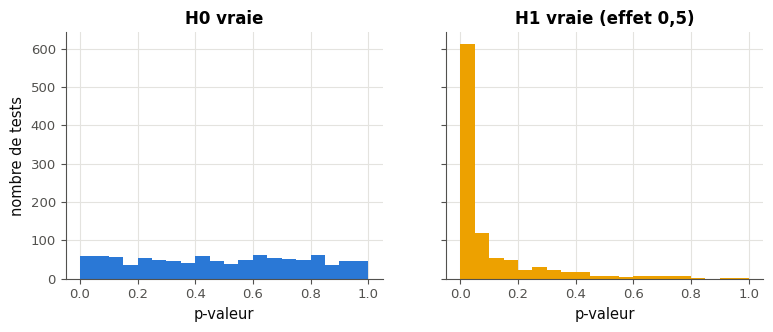

In [29]:
rng_21 = np.random.default_rng(821)
n_21 = 20
z_h0 = rng_21.normal(0, 1, size=(1000, n_21)).mean(axis=1) * math.sqrt(n_21)        # H0 true: mean 0, σ = 1
p_h0 = 2 * stats.norm.sf(np.abs(z_h0))
z_h1 = rng_21.normal(0.5, 1, size=(1000, n_21)).mean(axis=1) * math.sqrt(n_21)      # H1 true: mean 0.5
p_h1 = 2 * stats.norm.sf(np.abs(z_h1))
p_by_k = np.array([stats.binomtest(k, 10).pvalue for k in range(11)])                # the 11 possible p-values
p_binomial = p_by_k[rng_21.binomial(10, 0.5, size=1000)]                            # H0 true: p = 1/2
exact_b = float(np.sum(stats.binom.pmf(np.flatnonzero(p_by_k <= 0.05), 10, 0.5)))
print(f"a) z-test, H0 true: share of p-values ≤ 0.05 = {np.mean(p_h0 <= 0.05):.3f}")
print(f"b) binomial test (n = 10), H0 true: share = {np.mean(p_binomial <= 0.05):.3f} (exact: {exact_b:.4f})")
print(f"c) z-test, H1 true (effect 0.5): share = {np.mean(p_h1 <= 0.05):.3f}")
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
axes[0].hist(p_h0, bins=20, range=(0, 1), color="C0")
axes[0].set(title="H0 vraie", xlabel="p-valeur", ylabel="nombre de tests")
axes[1].hist(p_h1, bins=20, range=(0, 1), color="C3")
axes[1].set(title="H1 vraie (effet 0,5)", xlabel="p-valeur")
plt.show()

**Après l'expérience**, dans ta copie : relie a) et d) à la démonstration de M08.10. Pourquoi le test binomial sur 10 essais rejette-t-il moins souvent que 5 % sous $H_0$ (liste les issues qui font rejeter) ? Que mesure la part de c), et comment la faire grandir ?

💡 a) et d) Sous $H_0$, la p-valeur d'un test à statistique continue suit la loi uniforme sur $[0, 1]$ (M08.10) : environ 5 % des p-valeurs tombent sous 0,05, et l'histogramme est plat, aux fluctuations près. b) Avec 10 essais, seules les issues 0, 1, 9 et 10 donnent une p-valeur au plus égale à 0,05 : $P = \frac{2 \times (1 + 10)}{1024} \approx 0{,}021$. Un test discret est **conservateur** : son risque de type I réel est plus petit que le seuil. c) Sous $H_1$, la part des p-valeurs sous 0,05 est la **puissance** du test, environ $\Phi(0{,}5\sqrt{20} - 1{,}96) \approx 0{,}61$ ; l'histogramme s'entasse près de 0. Elle grandit avec l'effet et avec le nombre de mesures.

### Ex M08.22 — La puissance d'un test par permutation, selon l'effet et la taille des groupes 🔬 ★★ ⏱️ 25 min
**Objectif :** mesurer par simulation la puissance d'un test par permutation, et la comparer à celle d'un test $z$.  
**Prérequis :** fiche §3 et §4 ; Ex M08.17 · **Parcours :** C

La **puissance** d'un test est la probabilité qu'il rejette $H_0$ quand l'effet existe. Pour un test par permutation, elle n'a pas de formule : on la **mesure** par simulation. Écris `power(effect, n, n_sims=100, n_permutations=199, seed=0)`, qui suit exactement cette procédure :
1. `rng = np.random.default_rng(seed)`, un seul générateur ;
2. pour `sim` de 0 à `n_sims − 1` : `x = rng.normal(effect, 1, n)` puis `y = rng.normal(0, 1, n)` (dans cet ordre), puis `p = mymath.testing.permutation_test(x, y, n_permutations, alternative="greater", seed=sim)` ;
3. renvoie la proportion des `n_sims` p-valeurs au plus égales à 0,05, en `float`.

La vérification calcule (avec ta fonction `permutation_test` : écris d'abord M08.17) :
- a) `power(0, 10)` (2 décimales) ;
- b) `power(1.0, 10)` (2 décimales) ;
- c) `power(0.5, 20)` (2 décimales) ;
- d) parmi $n = 5$, 10 et 20, le plus petit nombre de mesures par groupe pour lequel `power(1.0, n)` atteint 0,8.

Une dernière cellule affiche la grille complète (effets 0 ; 0,5 ; 1 et $n$ = 5, 10, 20), à côté de la puissance du test $z$ unilatéral qui connaît $\sigma = 1$, $\Phi\big(\delta\sqrt{n/2} - z_{0{,}95}\big)$ : la différence de deux moyennes de $n$ mesures a l'écart-type $\sqrt{2/n}$.

Dans ta copie : que mesure a) ? Pourquoi ne vaut-il pas exactement 0,05 (pense à l'erreur type d'une proportion estimée sur 100 simulations) ? Comment la puissance évolue-t-elle avec l'effet, et avec $n$ ? Le test par permutation, qui ne suppose rien sur la loi des mesures, fait-il beaucoup moins bien que le test $z$ ?

In [30]:
def power(effect, n, n_sims=100, n_permutations=199, seed=0):
    """The share of n_sims simulated permutation tests (alternative="greater") whose p-value is at most 0.05."""
    rng = np.random.default_rng(seed)
    rejected = 0
    for sim in range(n_sims):
        x = rng.normal(effect, 1, n)
        y = rng.normal(0, 1, n)
        p = mymath.testing.permutation_test(x, y, n_permutations, alternative="greater", seed=sim)
        rejected += p <= 0.05
    return float(rejected / n_sims)


print("a)", power(0, 10), " b)", power(1.0, 10), " c)", power(0.5, 20))

a) 0.05  b) 0.68  c) 0.47


In [31]:
def power_variant_22(effect, n, swap=False, same_seed=False, n_sims=100, n_permutations=199, seed=0):
    """power() with a classic slip: y drawn before x, or the same seed for every permutation test."""
    rng = np.random.default_rng(seed)
    rejected = 0
    for sim in range(n_sims):
        if swap:
            y = rng.normal(0, 1, n)
            x = rng.normal(effect, 1, n)
        else:
            x = rng.normal(effect, 1, n)
            y = rng.normal(0, 1, n)
        p = mymath.testing.permutation_test(x, y, n_permutations, alternative="greater", seed=0 if same_seed else sim)
        rejected += p <= 0.05
    return float(rejected / n_sims)


SWAP_22 = "tire x, puis y, dans cet ordre, avec le même générateur"
SEED_22 = "chaque simulation appelle permutation_test avec sa propre graine : seed=sim"
wbm.record("M08.22a", power(0, 10), decimals=2,
           mistakes={SEED_22: power_variant_22(0, 10, same_seed=True)})
wbm.record("M08.22b", power(1.0, 10), decimals=2,
           mistakes={"la puissance est la part des p-valeurs au plus égales à 0,05, pas au-dessus":
                         1 - power(1.0, 10),
                     SWAP_22: power_variant_22(1.0, 10, swap=True),
                     SEED_22: power_variant_22(1.0, 10, same_seed=True)})
wbm.record("M08.22c", power(0.5, 20), decimals=2,
           mistakes={SWAP_22 + " ; ou compte les p-valeurs au plus égales à 0,05 (<=, pas <)":
                         power_variant_22(0.5, 20, swap=True),
                     SEED_22: power_variant_22(0.5, 20, same_seed=True)})
wbm.record("M08.22d", 20)

WBM_ANSWER {"decimals": 2, "hash": "180969772637caeb4d0c9c927e9be41392483ff5d5c6ed7d575723305d713670", "hash_coarse": "03e2d8a98dbdc49591ab3dc081abb70dd6eec94f820ceacc7ba6cc1e4bb96c35", "id": "M08.22a", "kind": "float", "magnitude": -2, "mistakes": {"26b1fc0e7da32c505a20d91c04537495d11e5645c3bd512b382fdb6c00f19432": "chaque simulation appelle permutation_test avec sa propre graine : seed=sim"}, "sign": 1}
📝 Ex M08.22a : réponse enregistrée (float, 2 décimales).


WBM_ANSWER {"coarse_any": {"0": ["40407c679570a4b7ae33cba147a45e57fb8394d44a119d7516745c6be47f7f2f"]}, "decimals": 2, "hash": "f98aa117ca25f2e7dfbd08f880529d40a84add9d1183224e30c573be8d2428ee", "hash_coarse": "099dcebbcd1629fca6e42a4fa52e21d64e10f3dc3265da327cb4cb40a2a708ff", "id": "M08.22b", "kind": "float", "magnitude": -1, "mistakes": {"2ca627ddb61663c58db88176c72a10e93e0fc3e9adab0e2a5104ebd9b045ef04": "la puissance est la part des p-valeurs au plus égales à 0,05, pas au-dessus", "a507f23efdcd2c8de3e9da21e516af94a17dc7b1284fcc36a8c1de41cf759829": "tire x, puis y, dans cet ordre, avec le même générateur", "b9e16026c21ce7caa2a058087c644a291a5f23849b41e08810d7d7eeb672e981": "chaque simulation appelle permutation_test avec sa propre graine : seed=sim"}, "sign": 1}
📝 Ex M08.22b : réponse enregistrée (float, 2 décimales).


WBM_ANSWER {"decimals": 2, "hash": "7252b75f92ddd7602edfc7a84e7b44ee2644a4d66eccb282f50127ee95ac27fd", "hash_coarse": "f7f51f5710f4da3fb447706d1cbd5509d5742312191878374727efdc524f171e", "id": "M08.22c", "kind": "float", "magnitude": -1, "mistakes": {"3a080d3a277304cfc0d908dcde04fa073edfacb04c11eb681643eaaadcdf0aaf": "chaque simulation appelle permutation_test avec sa propre graine : seed=sim", "be22037895ac2dbf00a11065fbfe9343969a2f145ed1743651de2414fdfae431": "tire x, puis y, dans cet ordre, avec le même générateur ; ou compte les p-valeurs au plus égales à 0,05 (<=, pas <)"}, "sign": 1}
📝 Ex M08.22c : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"hash": "a73dd8115d70e5cf70c26b183075c25ababadc3b842b19badc0b518d8dd6d3be", "id": "M08.22d", "kind": "int", "magnitude": 1, "sign": 1}
📝 Ex M08.22d : réponse enregistrée (int).


**La grille complète** (cette cellule utilise ta fonction).

In [32]:
grid_22 = {effect: [power(effect, n) for n in (5, 10, 20)] for effect in (0, 0.5, 1.0)}
print("effect · measured power for n = 5, 10, 20 · power of the z-test, Φ(δ√(n/2) − 1.645)")
for effect, measured in grid_22.items():
    theory = [NormalDist().cdf(effect * math.sqrt(n / 2) - NormalDist().inv_cdf(0.95)) for n in (5, 10, 20)]
    print(f"{effect:3.1f} · " + "  ".join(f"{m:.2f}" for m in measured) + " · "
          + "  ".join(f"{t:.2f}" for t in theory))

effect · measured power for n = 5, 10, 20 · power of the z-test, Φ(δ√(n/2) − 1.645)
0.0 · 0.05  0.05  0.08 · 0.05  0.05  0.05
0.5 · 0.18  0.28  0.47 · 0.20  0.30  0.47
1.0 · 0.39  0.68  0.95 · 0.47  0.72  0.94


💡 a) Sans effet, la puissance mesurée est le **risque de type I** : environ 0,05. Sur 100 simulations, son erreur type vaut $\sqrt{0{,}05 \times 0{,}95 / 100} \approx 0{,}022$ : 0,05 ou 0,08 sont aussi normaux l'un que l'autre. b) et c) La puissance grandit avec l'effet et avec $n$ : environ 0,7 pour un effet de 1 avec 10 mesures par groupe, près de 0,95 avec 20. d) Il faut 20 mesures par groupe pour dépasser 0,8 avec un effet de 1. La grille suit de près la puissance du test $z$, qui connaît pourtant $\sigma$ : le test par permutation perd peu, et il ne suppose rien sur la loi des mesures.

### Ex M08.23 — La loi de la statistique sous H0, et la p-valeur comme une aire 🎨 ★ ⏱️ 15 min
**Objectif :** tracer la loi exacte d'une statistique de permutation sous $H_0$, et y lire la p-valeur comme la part des répartitions au moins aussi extrêmes.  
**Prérequis :** fiche §1 et §3 ; R0 (matplotlib) ; R8 (combinaisons) · **Parcours :** C

Écris `draw_null_distribution(ax, x, y)`, qui, pour deux petits échantillons :
1. calcule l'écart observé $t = \bar{x} - \bar{y}$ et sa loi **exacte** sous $H_0$ : les valeurs de $t_{\text{perm}}$ pour **toutes** les répartitions des valeurs réunies (`x` puis `y`) en un groupe de `len(x)` valeurs et un groupe de `len(y)` valeurs (`itertools.combinations(range(len(pooled)), len(x))` donne les indices du premier groupe) ;
2. trace dans `ax` l'histogramme de ces valeurs, avec, d'une autre couleur, les répartitions au moins aussi extrêmes que l'observation ($t_{\text{perm}} \ge t - 10^{-9}$), et une ligne verticale à $t$ (`ax.axvline`) ;
3. renvoie la p-valeur exacte unilatérale : la part de ces répartitions au moins aussi extrêmes, en `float`.

La cellule de la figure s'en sert pour les durées (en minutes) d'un même trajet, fait cinq jours par un itinéraire, $x = (31, 27, 34, 29, 33)$, et cinq autres jours par un autre, $y = (26, 28, 25, 30, 24)$. Une cellule de vérification essaie ta fonction sur un autre dataset, dans un axe neuf (la figure elle-même se juge à l'œil).

Dans ta copie : combien y a-t-il de répartitions ? Que vaut la p-valeur, et à quelle partie de la figure correspond-elle ? Pourquoi la loi est-elle symétrique autour de 0 quand les deux groupes ont la même taille ?

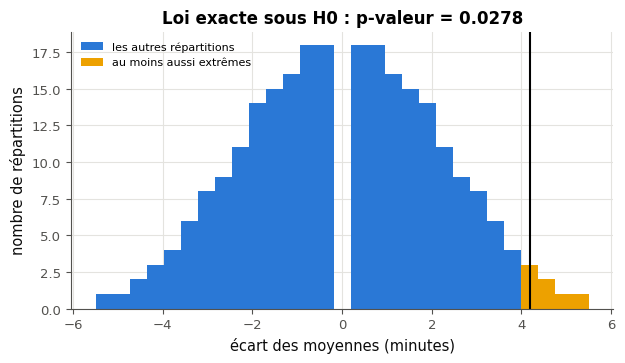

In [33]:
def draw_null_distribution(ax, x, y):
    """In ax, the histogram of mean(group 1) − mean(group 2) over every split of the pooled values, the splits at least
    as extreme as the observed difference in another color, and a vertical line at it; return the exact one-sided
    p-value (alternative "greater")."""
    pooled = np.concatenate([np.asarray(x, dtype=float), np.asarray(y, dtype=float)])
    m = len(x)
    observed = pooled[:m].mean() - pooled[m:].mean()
    values = []
    for idx in itertools.combinations(range(len(pooled)), m):
        mask = np.zeros(len(pooled), dtype=bool)
        mask[list(idx)] = True
        values.append(pooled[mask].mean() - pooled[~mask].mean())
    values = np.array(values)
    extreme = values >= observed - 1e-9
    bins = np.linspace(values.min() - 0.1, values.max() + 0.1, 30)
    ax.hist(values[~extreme], bins=bins, color="C0", label="les autres répartitions")
    ax.hist(values[extreme], bins=bins, color="C3", label="au moins aussi extrêmes")
    ax.axvline(observed, color="black", lw=1.5)
    ax.legend(fontsize=8)
    return float(np.mean(extreme))


fig, ax = plt.subplots(figsize=(7, 3.6))
p_23 = draw_null_distribution(ax, [31, 27, 34, 29, 33], [26, 28, 25, 30, 24])
ax.set(xlabel="écart des moyennes (minutes)", ylabel="nombre de répartitions",
       title=f"Loi exacte sous H0 : p-valeur = {p_23:.4f}")
plt.show()

**Vérifications automatiques** (sur un autre dataset, dans un axe neuf).

In [34]:
with checked("M08.23 vérifications"):
    import matplotlib.colors as mcolors
    problems = []
    X2_23, Y2_23 = [4.2, 5.1, 3.8, 4.9], [3.9, 4.4, 3.1, 4.0, 3.6, 3.3]
    pooled_t = X2_23 + Y2_23
    observed_t = np.mean(X2_23) - np.mean(Y2_23)
    splits_t = [np.mean([pooled_t[i] for i in idx]) - np.mean([pooled_t[i] for i in range(10) if i not in idx])
                for idx in itertools.combinations(range(10), 4)]
    exact_t = sum(t >= observed_t - 1e-9 for t in splits_t) / len(splits_t)
    fig_t, ax_t = plt.subplots()
    returned_t = []
    try:
        created = drawn(lambda: returned_t.append(draw_null_distribution(ax_t, X2_23, Y2_23)))
    except BaseException:
        plt.close(fig_t)
        raise
    lines_t = [line for line in ax_t.get_lines()
               if len(set(np.round(np.asarray(line.get_xdata(), dtype=float), 9))) == 1]
    colors_t = {mcolors.to_hex(patch.get_facecolor()) for patch in ax_t.patches
                if getattr(patch, "get_height", lambda: 0)() > 0}
    plt.close(fig_t)
    if created:
        problems.append("draw_null_distribution ouvre sa propre figure (plt.figure ou plt.subplots) : dessine dans "
                        "l'axe reçu")
    elif not returned_t or returned_t[0] is None:
        problems.append("draw_null_distribution ne renvoie rien : il manque return (la p-valeur exacte)")
    elif not isinstance(returned_t[0], (int, float)) or abs(float(returned_t[0]) - exact_t) > 1e-9:
        problems.append(f"la p-valeur renvoyée, {returned_t[0]}, n'est pas la part des {len(splits_t)} "
                        "répartitions au moins aussi extrêmes que l'observation (t_perm ≥ t − 1e-9)")
    elif not any(abs(float(np.asarray(line.get_xdata(), dtype=float)[0]) - observed_t) < 1e-6 for line in lines_t):
        problems.append("aucune ligne verticale à l'écart observé : ax.axvline(t)")
    elif len(colors_t) < 2:
        problems.append("les répartitions au moins aussi extrêmes doivent avoir une autre couleur que les autres")
    if problems:
        print("❌ Ex M08.23 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex M08.23 : la loi exacte, la ligne de l'écart observé et la p-valeur sont justes, sur un autre "
              "dataset.")

✅ Ex M08.23 : la loi exacte, la ligne de l'écart observé et la p-valeur sont justes, sur un autre dataset.


💡 Il y a $\binom{10}{5} = 252$ répartitions. L'écart observé vaut $30{,}8 - 26{,}6 = 4{,}2$ minutes, et 7 répartitions sur 252 font au moins aussi bien : $p = \frac{7}{252} = \frac{1}{36} \approx 0{,}028$, la part des barres rouges dans l'histogramme. Avec deux groupes de même taille, échanger les deux groupes change $t$ en $-t$ : chaque valeur a sa symétrique, et la loi est symétrique autour de 0.

## Partie C · Erreurs classiques, savoir-faire et défi

Fiche §1 à §6. Trois erreurs à trouver, le test automatique d'un test, puis une sélection de features parmi cinquante.

### Ex M08.24 — Chasse à l'erreur : une p-valeur nulle, un test unilatéral choisi après coup, Bonferroni à l'envers 🐛 ★ ⏱️ 15 min
**Objectif :** repérer dans du code les erreurs classiques sur les p-valeurs, puis calculer les bonnes valeurs.  
**Prérequis :** fiche §2, §3, §5 et §6 · **Parcours :** C

Un collègue a écrit six lignes, chacune avec un commentaire qui dit ce qu'elle doit calculer. Trois lignes ne calculent pas ce que dit leur commentaire. **Sans exécuter de code**, trouve-les.

```python
B, C = 999, 0                                       # random permutations, and draws at least as extreme as observed
p_perm = C / B                                      # (A) the p-value of this permutation test
p_tail = sum(math.comb(18, j) for j in range(14, 19)) / 2 ** 18    # (B) P(K ≥ 14) for K of law B(18, 1/2)
p_values = [0.004, 0.02, 0.3]                       # the p-values of a family of three tests
adjusted = min(p_values) / len(p_values)            # (C) the Bonferroni-adjusted p-value of the smallest one
z_975 = NormalDist().inv_cdf(0.975)                 # (D) the quantile of a two-sided 95 % interval
p_two = 1 - NormalDist().cdf(abs(-1.8))             # (E) the two-sided p-value of z = −1.8 (H1 two-sided, set in advance)
half = z_975 * math.sqrt(0.3 * 0.7 / 50)            # (F) the half-width of Wald's 95 % interval, p̂ = 0.3, n = 50
```

Questions :
- a) les lettres des lignes fausses, dans l'ordre alphabétique (un texte) ;
- b) pour chacune des six lignes, de (A) à (F), la bonne valeur de ce que dit son commentaire (une liste de 6 nombres, 3 décimales).

Dans ta copie : pour chaque ligne fausse, quelle erreur a été faite, et comment la corriger ? Pourquoi l'erreur (E) revient-elle à choisir un test unilatéral **après** avoir vu le signe de $z$, et que vaut alors le vrai risque de type I d'une règle « rejeter si cette valeur est sous 0,05 » ?

In [35]:
answer_M08_24a = "ACE"
B, C = 999, 0
p_perm = (C + 1) / (B + 1)                          # (A) never 0: the observed split counts as a draw
p_tail = sum(math.comb(18, j) for j in range(14, 19)) / 2 ** 18    # (B) correct
p_values = [0.004, 0.02, 0.3]
adjusted = min(1, min(p_values) * len(p_values))    # (C) multiply by m, do not divide
z_975 = NormalDist().inv_cdf(0.975)                 # (D) correct
p_two = 2 * (1 - NormalDist().cdf(abs(-1.8)))       # (E) count both tails
half = z_975 * math.sqrt(0.3 * 0.7 / 50)            # (F) correct
answer_M08_24b = [p_perm, p_tail, adjusted, z_975, p_two, half]
print(answer_M08_24a, [round(value, 4) for value in answer_M08_24b])

ACE [0.001, 0.0154, 0.012, 1.96, 0.0719, 0.127]


In [36]:
wbm.record("M08.24a", "ACE",
           mistakes={"il manque une ligne fautive : refais chaque calcul de p-valeur par permutation sur un petit exemple": "CE",
                     "il manque une ligne fautive : refais chaque correction de Bonferroni sur un petit exemple": "AE",
                     "il manque une ligne fautive : refais chaque p-valeur bilatérale sur un petit exemple": "AC",
                     "une ligne de trop : une des lignes que tu cites est correcte ; refais le calcul de chacune sur un petit exemple": {"ABCE", "ACDE", "ACEF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : refais chaque calcul de p-valeur par permutation sur un petit exemple": {"BCE", "CDE", "CEF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : refais chaque correction de Bonferroni sur un petit exemple": {"ABE", "ADE", "AEF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : refais chaque p-valeur bilatérale sur un petit exemple": {"ABC", "ACD", "ACF"},
                     "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple": {"A", "C", "E"},
                     "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple": {"B", "D", "F", "AB", "AD", "AF", "BC", "BD", "BE", "BF", "CD", "CF", "DE", "DF", "EF", "ABD", "ABF", "ADF", "BCD", "BCF", "BDE", "BDF", "BEF", "CDF", "DEF", "ABCD", "ABCF", "ABDE", "ABDF", "ABEF", "ACDF", "ADEF", "BCDE", "BCDF", "BCEF", "BDEF", "CDEF", "ABCDF", "ABDEF", "BCDEF"},
                     "plusieurs lignes que tu cites sont correctes : vérifie chacune avec un petit exemple": {"ABCDE", "ABCEF", "ACDEF", "ABCDEF"}})
VALUES_24 = [1 / 1000, 4048 / 2 ** 18, 0.012, NormalDist().inv_cdf(0.975), 2 * (1 - NormalDist().cdf(1.8)),
             NormalDist().inv_cdf(0.975) * math.sqrt(0.21 / 50)]
wbm.record("M08.24b", VALUES_24, decimals=3,
           mistakes={"(A) : la p-valeur d'un test par permutation tiré au hasard n'est jamais nulle":
                         [0] + VALUES_24[1:],
                     "(C) : la p-valeur ajustée multiplie p par m":
                         VALUES_24[:2] + [0.004 / 3] + VALUES_24[3:],
                     "(E) : une p-valeur bilatérale compte les deux côtés":
                         VALUES_24[:4] + [1 - NormalDist().cdf(1.8)] + VALUES_24[5:]})

WBM_ANSWER {"hash": "87d6f725621fd63bfeedf6cb6ce0b6858a621b267b2e5e9414940492b1657724", "id": "M08.24a", "kind": "str", "mistakes": {"131d0af4c1ceacc9299feadf5dcc799874b65686a2d24fa5121045a952610376": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "13e9660975ab390795583ff6777f0a03e828bb38cf21dac88451cdd0ec1f9dd2": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "140c048a1238a4979f9b7c76db173deace0f47ec904860cf01a50ea29c6e7a54": "il manque une ligne fautive : refais chaque calcul de p-valeur par permutation sur un petit exemple", "1b7715f75a7bb620a3cb0e67a088f00db948127858d471a7dcec03f6f20d03fc": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "1b957df8c056285195be11f73b9b25a1b36efb7206fa16134094845e011bc8a8": "il manque des lignes fautives, et des lignes que tu cites

💡 (A) Avec $C = 0$, la ligne annonce une p-valeur nulle ; la bonne est $\frac{C + 1}{B + 1} = 0{,}001$. (B) est juste : $\frac{3060 + 816 + 153 + 18 + 1}{2^{18}} = \frac{4048}{262\,144} \approx 0{,}015$. (C) divise au lieu de multiplier : la p-valeur ajustée vaut $\min(1, 3 \times 0{,}004) = 0{,}012$. (D) est juste, 1,960. (E) ne compte qu'un côté : la p-valeur bilatérale vaut $2\big(1 - \Phi(1{,}8)\big) \approx 0{,}072$, pas 0,036. Prendre toujours le côté où tombe $z$, c'est choisir le test unilatéral après coup : la règle « rejeter si $1 - \Phi(|z|) \le 0{,}05$ » rejette quand $|z| \ge 1{,}645$, avec un risque de type I réel de 10 %, le double du seuil annoncé. (F) est juste : $1{,}96\sqrt{0{,}21/50} \approx 0{,}127$.

### Ex M08.25 — Tester un test : un pytest qui vérifie l'uniformité des p-valeurs sous H0 🛠️ ★ ⏱️ 15 min
**Objectif :** écrire le test automatique d'un test statistique : sous $H_0$, la part des p-valeurs sous le seuil doit être proche du seuil, à une tolérance comptée en erreurs types.  
**Prérequis :** fiche §1 et §4 ; Ex M08.21 ; M02c (Ex M02c.27) · **Parcours :** C

Comment vérifier qu'un test est **bien calibré**, c'est-à-dire que, sous $H_0$, il rejette au seuil de 5 % dans 5 % des cas ? Par simulation (M08.10 et M08.21) : on tire beaucoup d'échantillons sous $H_0$, on calcule leurs p-valeurs, et la part des p-valeurs au plus égales à 0,05 doit être proche de 0,05. Proche à combien près ? Comme en M02c.27 : à $k$ erreurs types près, avec l'erreur type d'une proportion, $\sqrt{\frac{\alpha(1 - \alpha)}{N}}$ pour $N$ simulations.

La cellule fournie définit `z_test_p_values(samples)`, les p-valeurs bilatérales du test $z$ de $H_0$ : « la moyenne vaut 0 » ($\sigma = 1$ connu), une par ligne de `samples`, et deux copies fausses. Écris :
- `K_SE` : le nombre d'erreurs types que ton test tolère. Un vrai projet lance ses tests des milliers de fois : la bonne fonction ne doit presque jamais échouer ; mais une copie qui rejette deux fois trop souvent, ou presque jamais, s'écarte de 0,05 d'une quinzaine d'erreurs types, et doit être attrapée à coup sûr ;
- `assert_calibrated(p_value_function, seed, n_sims=4000, n=20, alpha=0.05)` : tire `samples = np.random.default_rng(seed).normal(0, 1, size=(n_sims, n))` ($H_0$ vraie), calcule `p = p_value_function(samples)`, et **lève une `AssertionError`** (`assert condition, message`) si la part des p-valeurs au plus égales à `alpha` s'écarte de `alpha` de plus de `K_SE` erreurs types ; le message dit ce qui était attendu, puis ce qui a été obtenu ;
- `test_z_test_is_calibrated()` : le test au format pytest, sans argument, qui appelle `assert_calibrated` sur `z_test_p_values` avec une graine fixe. Dans un fichier `tests/test_….py`, pytest trouverait cette fonction et la lancerait tout seul.

La vérification lance `assert_calibrated` sur la bonne fonction et sur les deux copies fausses, pour 30 graines : la bonne doit passer **toutes** les fois, les fausses doivent échouer **toutes** les fois.

Dans ta copie : quel `K_SE` as-tu choisi, et pourquoi ? Quelle erreur chacune des deux copies fait-elle, et dans quel sens se trompe-t-elle ? Une troisième copie, qui renverrait `1 - p`, passerait ton test : pourquoi (que vaut la loi de $1 - P$ quand $P$ est uniforme sur $[0, 1]$) ? Que faudrait-il vérifier en plus pour l'attraper ?

In [37]:
def z_test_p_values(samples):
    """Two-sided p-values of the z-test of H0: mean = 0 (σ = 1 known), one per row of samples."""
    samples = np.asarray(samples, dtype=float)
    z = samples.mean(axis=1) * math.sqrt(samples.shape[1])
    return 2 * stats.norm.sf(np.abs(z))


def z_test_copy_1(samples):            # a copy with a bug
    samples = np.asarray(samples, dtype=float)
    z = samples.mean(axis=1) * math.sqrt(samples.shape[1])
    return stats.norm.sf(np.abs(z))


def z_test_copy_2(samples):            # a copy with another bug
    samples = np.asarray(samples, dtype=float)
    z = samples.mean(axis=1) / math.sqrt(samples.shape[1])
    return 2 * stats.norm.sf(np.abs(z))

In [38]:
K_SE = 5      # 2 (1 − Φ(5)) ≈ 6e-7: never flaky in practice; a copy 10 standard errors away is always caught


def assert_calibrated(p_value_function, seed, n_sims=4000, n=20, alpha=0.05):
    """Raise an AssertionError unless, under H0, the share of p-values <= alpha is within K_SE standard errors of alpha."""
    samples = np.random.default_rng(seed).normal(0, 1, size=(n_sims, n))
    share = float(np.mean(np.asarray(p_value_function(samples)) <= alpha))
    standard_error = math.sqrt(alpha * (1 - alpha) / n_sims)
    assert abs(share - alpha) <= K_SE * standard_error, (
        f"expected a share of p-values <= {alpha} within {K_SE} standard errors ({K_SE * standard_error:.4f}) of "
        f"{alpha} under H0, got {share:.4f}")


def test_z_test_is_calibrated():
    """The pytest test: assert_calibrated on z_test_p_values, with a fixed seed."""
    assert_calibrated(z_test_p_values, seed=2025)


for name, function in [("z_test_p_values", z_test_p_values), ("copy 1", z_test_copy_1), ("copy 2", z_test_copy_2)]:
    share = np.mean(function(np.random.default_rng(0).normal(0, 1, size=(4000, 20))) <= 0.05)
    print(f"{name}: share of p-values <= 0.05 under H0 = {share:.4f}")

z_test_p_values: share of p-values <= 0.05 under H0 = 0.0530
copy 1: share of p-values <= 0.05 under H0 = 0.1022
copy 2: share of p-values <= 0.05 under H0 = 0.0000


In [39]:
with checked("M08.25 vérifications"):
    problems = []
    if K_SE is ...:
        raise NotImplementedError("choisis K_SE, le nombre d'erreurs types que ton test tolère")
    if isinstance(K_SE, bool) or not isinstance(K_SE, (int, float)):
        raise TypeError(f"K_SE doit être un nombre, pas {type(K_SE).__name__}")
    seen = []

    def spy(samples):                                   # records the first value of the samples it receives
        seen.append(float(np.asarray(samples)[0, 0]))
        return z_test_p_values(samples)

    def outcome(function, seed):
        """None if assert_calibrated passes, else the message of its AssertionError."""
        try:
            assert_calibrated(function, seed)
        except AssertionError as exc:
            return str(exc)
        return None

    outcome(spy, 7)
    if not seen or seen[0] != float(np.random.default_rng(7).normal(0, 1, size=(4000, 20))[0, 0]):
        problems.append("assert_calibrated doit tirer samples = np.random.default_rng(seed).normal(0, 1, size=(n_sims, "
                        "n)) avec la graine reçue : un test doit être reproductible")
    else:
        passed = sum(outcome(z_test_p_values, seed) is None for seed in range(30))
        messages_1 = [outcome(z_test_copy_1, seed) for seed in range(30)]
        messages_2 = [outcome(z_test_copy_2, seed) for seed in range(30)]
        caught_1 = sum(message is not None for message in messages_1)
        caught_2 = sum(message is not None for message in messages_2)
        print(f"K_SE = {K_SE} : la bonne fonction passe ton test {passed} fois sur 30 ; la copie 1 est attrapée "
              f"{caught_1} fois sur 30, la copie 2 {caught_2} fois sur 30")
        if passed < 30:
            problems.append("ton test échoue sur la bonne fonction pour certaines graines : la tolérance est trop "
                            "étroite (un test qui échoue sans bug est « instable », flaky)")
        if caught_1 < 30:
            problems.append("ton test laisse passer la copie 1 : la tolérance est trop large")
        if caught_2 < 30:
            problems.append("ton test laisse passer la copie 2 : un test peut aussi se tromper en rejetant trop "
                            "rarement ; regarde l'écart à alpha dans les deux sens")
        if not problems and any(not message.strip() for message in messages_1 + messages_2):
            problems.append("ajoute un message à ton assert (assert condition, message) : il dit ce qui était attendu "
                            "et ce qui a été obtenu")
        if not problems and K_SE < 4:
            problems.append("ces 30 graines passent, mais ce K_SE est trop petit : sur des milliers de lancements, la "
                            "bonne fonction échouerait de temps en temps (avec la probabilité 2(1 − Φ(K_SE)))")
        if not problems and K_SE > 8:
            problems.append("ces 30 graines passent, mais ce K_SE est trop grand : sur des milliers de lancements, une "
                            "copie qui rejette deux fois trop souvent passerait de temps en temps")
        if not problems:
            try:
                test_z_test_is_calibrated()
            except AssertionError as exc:
                problems.append(f"test_z_test_is_calibrated échoue sur la bonne fonction : {exc}")
    if problems:
        print("❌ Ex M08.25 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex M08.25 : ton test accepte la bonne fonction et attrape les deux copies fausses, pour 30 graines.")

K_SE = 5 : la bonne fonction passe ton test 30 fois sur 30 ; la copie 1 est attrapée 30 fois sur 30, la copie 2 30 fois sur 30
✅ Ex M08.25 : ton test accepte la bonne fonction et attrape les deux copies fausses, pour 30 graines.


💡 L'erreur type vaut $\sqrt{0{,}05 \times 0{,}95 / 4000} \approx 0{,}0034$. Un $K_{SE}$ entre 4 et 8 convient : la bonne fonction échoue avec la probabilité $2\big(1 - \Phi(K_{SE})\big)$, $6 \times 10^{-5}$ pour 4 et $6 \times 10^{-7}$ pour 5. La copie 1 oublie le facteur 2 : elle renvoie la p-valeur unilatérale du côté observé, et rejette dans 10 % des cas (l'erreur (E) de M08.24) ; elle se trompe dans le sens dangereux, celui des faux positifs. La copie 2 divise la moyenne par $\sqrt{n}$ au lieu de la multiplier : $z$ est 20 fois trop petit, et le test ne rejette presque jamais ; il ne donne pas de faux positifs, mais il n'a plus de puissance. Les deux s'écartent de 0,05 d'environ 14 erreurs types, dans un sens ou dans l'autre : il faut comparer l'écart **en valeur absolue**. La copie `1 - p` passerait : si $P$ est uniforme, $1 - P$ l'est aussi. Elle ne se trahit que sous $H_1$, où elle ne rejette presque jamais : un test complet vérifie aussi la puissance sur un cas où l'effet existe.

### Ex M08.26 — Défi : retrouver les trois vraies features parmi cinquante, avec au plus un faux positif 🏆 ★★★ ⏱️ 25 min
**Objectif :** choisir une règle de décision pour 50 tests à la fois, qui trouve les vraies features sans se laisser piéger par le bruit.  
**Prérequis :** fiche §6 ; Ex M08.7, M08.11 et M08.19 · **Parcours :** C

Un dataset a 200 exemples et 50 features ; quelques-unes seulement sont liées à la cible $y$, les autres sont du bruit. Écris `select_features(X, y)`, qui renvoie la liste des indices des features que tu déclares liées à la cible.

**L'objectif** : sur `X_26, y_26`, qui a trois vraies features, et sur quatre autres datasets du même type, dont le nombre de vraies features (de 1 à 4) n'est pas donné à ta fonction, retrouver **toutes** les vraies features, avec **au plus un** faux positif par dataset, en moins de 10 secondes par dataset.

Une piste : un test par feature (la p-valeur de la corrélation de $x_j$ avec $y$, `stats.pearsonr(X[:, j], y).pvalue`), puis une règle de décision. Laquelle ? Ce chapitre a tout ce qu'il faut.

La vérification essaie ta fonction sur les cinq datasets ; une dernière cellule enregistre si l'objectif est atteint sur les cinq.

Dans ta copie : combien de features la règle « $p \le 0{,}05$ » déclare-t-elle liées sur `X_26`, et combien de faux positifs attendais-tu (M08.7) ? Pourquoi « garder les trois plus fortes corrélations » n'est-il pas une bonne règle ? Explique ta règle : que garantit-elle, et quel risque prend-elle ?

In [40]:
def make_dataset(seed, n_true, n=200, p=50):
    """X (n × p), y and the sorted indices of the n_true features related to y (the other features are noise)."""
    rng = np.random.default_rng(seed)
    X = np.round(rng.normal(size=(n, p)), 3)
    true = np.sort(rng.choice(p, size=n_true, replace=False))
    coef = rng.uniform(0.95, 1.2, size=n_true) * rng.choice([-1, 1], size=n_true)
    y = X[:, true] @ coef + rng.normal(0, math.sqrt(6.25 - np.sum(coef ** 2)), size=n)
    return X, np.round(y, 3), true


X_26, y_26, _ = make_dataset(826, 3)          # three true features, whose indices stay hidden

In [41]:
def select_features(X, y, alpha=0.05):
    """The indices of the features whose correlation with y stays significant after Bonferroni's correction."""
    X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float)
    p_values = [stats.pearsonr(X[:, j], y).pvalue for j in range(X.shape[1])]
    adjusted = mymath.testing.bonferroni(p_values)
    return [int(j) for j in np.flatnonzero(adjusted <= alpha)]


def naive_rule(X, y):
    return [j for j in range(X.shape[1]) if stats.pearsonr(X[:, j], y).pvalue <= 0.05]


def top_three(X, y):
    correlations = np.abs([np.corrcoef(X[:, j], y)[0, 1] for j in range(X.shape[1])])
    return sorted(int(j) for j in np.argsort(correlations)[-3:])


for seed_t, n_true_t in [(826, 3), (21, 2), (22, 4), (23, 1), (24, 3)]:
    X_t, y_t, true_t = make_dataset(seed_t, n_true_t)
    print(f"true {true_t.tolist()} · Bonferroni {select_features(X_t, y_t)} · p ≤ 0.05 {naive_rule(X_t, y_t)}"
          f" · top three {top_three(X_t, y_t)}")

true [0, 41, 44] · Bonferroni [0, 41, 44] · p ≤ 0.05 [0, 9, 41, 44] · top three [0, 41, 44]
true [12, 20] · Bonferroni [12, 20] · p ≤ 0.05 [12, 20, 34, 46] · top three [12, 20, 34]


true [7, 15, 19, 32] · Bonferroni [7, 15, 19, 32] · p ≤ 0.05 [1, 2, 7, 13, 15, 19, 28, 32, 35, 39, 43] · top three [7, 15, 32]


true [3] · Bonferroni [3] · p ≤ 0.05 [3, 17, 40] · top three [3, 17, 40]


true [5, 24, 41] · Bonferroni [5, 24, 41] · p ≤ 0.05 [5, 6, 15, 24, 34, 41] · top three [5, 24, 41]


In [42]:
wbm.record("M08.26", True,
           mistakes={"l'objectif n'est pas atteint sur les cinq datasets : la cellule du défi dit pourquoi":
                         False})

WBM_ANSWER {"hash": "e6a15ac9fc5b2f7340c803901a98337dafbed0a32add01d9fdbeb3788044f840", "id": "M08.26", "kind": "bool", "mistakes": {"20e03f11374f7264807792b05dd86dced6a6dae3e83f46c538197ce3ee8ec71e": "l'objectif n'est pas atteint sur les cinq datasets : la cellule du défi dit pourquoi"}}
📝 Ex M08.26 : réponse enregistrée (bool).


In [43]:
with checked("M08.26 défi"):
    import time
    problems, results_26, ok_26, slowest = [], [], False, 0.0
    for seed_t, n_true_t in [(826, 3), (21, 2), (22, 4), (23, 1), (24, 3)]:
        X_t, y_t, true_t = make_dataset(seed_t, n_true_t)
        start_t = time.perf_counter()
        try:
            chosen_t = select_features(X_t.copy(), y_t.copy())
        except NotImplementedError:
            raise
        except Exception as exc:  # noqa: BLE001
            problems.append(f"select_features lève {type(exc).__name__} ({exc})")
            break
        slowest = max(slowest, time.perf_counter() - start_t)
        if chosen_t is None:
            problems.append("select_features ne renvoie rien : il manque return")
            break
        chosen_t = {int(j) for j in np.asarray(chosen_t, dtype=int).ravel()}
        results_26.append((len(set(true_t.tolist()) - chosen_t), len(chosen_t - set(true_t.tolist()))))
    if not problems:
        print("par dataset (vraies features manquées, faux positifs) :", results_26)
        missing_26 = any(missed > 0 for missed, _ in results_26)
        extra_26 = any(false > 1 for _, false in results_26)
        both_26 = any(missed > 0 and false > 1 for missed, false in results_26)
        if both_26:
            problems.append("sur un même dataset, des vraies features manquent et des fausses sont gardées : vérifie "
                            "que tu renvoies les indices des colonnes (de 0 à 49)")
        elif missing_26 and extra_26:
            problems.append("ta règle manque des vraies features sur certains datasets et garde plus d'un faux positif "
                            "sur d'autres : elle ne s'adapte pas au nombre de vraies features")
        elif missing_26:
            problems.append("des vraies features manquent : ta règle est trop sévère")
        elif extra_26:
            problems.append("plus d'un faux positif sur un dataset : ta règle est trop permissive")
        if slowest > 10:
            problems.append(f"objectif atteint, mais en {slowest:.1f} s pour un dataset (objectif : 10 s)")
    if problems:
        print("❌ Ex M08.26 : " + " ; ".join(problems) + ".")
    else:
        ok_26 = True
        print("✅ Ex M08.26 : défi réussi : toutes les vraies features, et au plus un faux positif, sur les cinq datasets.")

par dataset (vraies features manquées, faux positifs) : [(0, 0), (0, 0), (0, 0), (0, 0), (0, 0)]
✅ Ex M08.26 : défi réussi : toutes les vraies features, et au plus un faux positif, sur les cinq datasets.


💡 La règle « $p \le 0{,}05$ » trouve les vraies features, mais aussi des faux positifs : sur 47 features de bruit, on en attend $47 \times 0{,}05 \approx 2{,}4$ (sept sur l'un des datasets). Garder les trois plus fortes corrélations suppose de connaître le nombre de vraies features : elle en manque une sur le dataset qui en a quatre, et ajoute des faux positifs sur ceux qui en ont une ou deux. La correction de Bonferroni (rejeter quand $50\,p_j \le 0{,}05$) garantit que la probabilité d'au moins un faux positif reste sous 5 %, quelle que soit la dépendance entre les tests (M08.11) ; son risque est de manquer une vraie feature faible, ce qui n'arrive pas ici : la plus faible a une corrélation d'environ 0,35, et son test a une p-valeur ajustée bien plus petite que 0,05.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu poser $H_0$ et $H_1$, et dire ce qu'une p-valeur mesure et ce qu'elle ne mesure pas ?
2. Sais-tu calculer la p-valeur exacte d'un test binomial et celle d'un petit test par permutation ?
3. Sais-tu calculer un risque de type I, une puissance, et le nombre d'observations nécessaire ?
4. Sais-tu calculer les intervalles de Wald, de Wilson et de Student apparié, et dire quand Wald échoue ?
5. Sais-tu corriger des comparaisons multiples par Bonferroni, et comparer deux modèles par l'AIC, le BIC et un facteur de Bayes ?

**La suite** : le chapitre 8 de workbookIA (entraînement et test : jeu de test, validation croisée, comparer deux modèles), puis M09a, les matrices et les systèmes linéaires.